**PHASE 1**

**RESNET 3D**

Using device: cuda
GPU: Tesla P100-PCIE-16GB
Total .npz files: 3119
Valid files (modic 0 or 2): 3095

Split → Train:2166 Val:464 Test:465

Building Train dataset:
  Loaded 2166 samples | skipped 0
Building Val dataset:
  Loaded 464 samples | skipped 0
Building Test dataset:
  Loaded 465 samples | skipped 0

ResNet3D params: 14,332,105
Epoch 01/25  |  Train 3.6018  |  Val 3.5662
  ✔ Saved best model
Epoch 02/25  |  Train 3.5092  |  Val 3.4358
  ✔ Saved best model
Epoch 03/25  |  Train 3.4198  |  Val 3.3800
  ✔ Saved best model
Epoch 04/25  |  Train 3.2964  |  Val 3.2130
  ✔ Saved best model
Epoch 05/25  |  Train 3.1916  |  Val 3.2914
Epoch 06/25  |  Train 3.0716  |  Val 3.1962
  ✔ Saved best model
Epoch 07/25  |  Train 3.0049  |  Val 3.0934
  ✔ Saved best model
Epoch 08/25  |  Train 2.8951  |  Val 3.0120
  ✔ Saved best model
Epoch 09/25  |  Train 2.8107  |  Val 2.9290
  ✔ Saved best model
Epoch 10/25  |  Train 2.7001  |  Val 2.8502
  ✔ Saved best model
Epoch 11/25  |  Train 2.6031  |  V

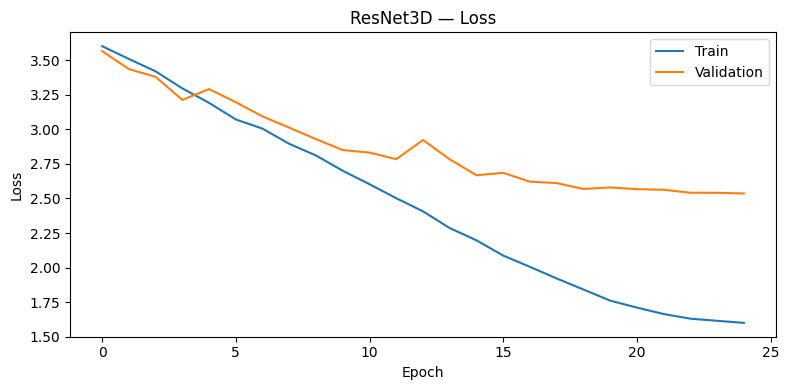


MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.8043    0.8662    0.8341       299
     Modic 2     0.7183    0.6182    0.6645       165

    accuracy                         0.7780       464
   macro avg     0.7613    0.7422    0.7493       464
weighted avg     0.7738    0.7780    0.7738       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.6739    0.4133    0.5124        75
          P2     0.5426    0.5730    0.5574        89
          P3     0.5145    0.6449    0.5723       138
          P4     0.4771    0.5253    0.5000        99
          P5     0.5952    0.3968    0.4762        63

    accuracy                         0.5345       464
   macro avg     0.5606    0.5107    0.5237       464
weighted avg     0.5486    0.5345    0.5313       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.8308    0.7489    0.7877       223
         

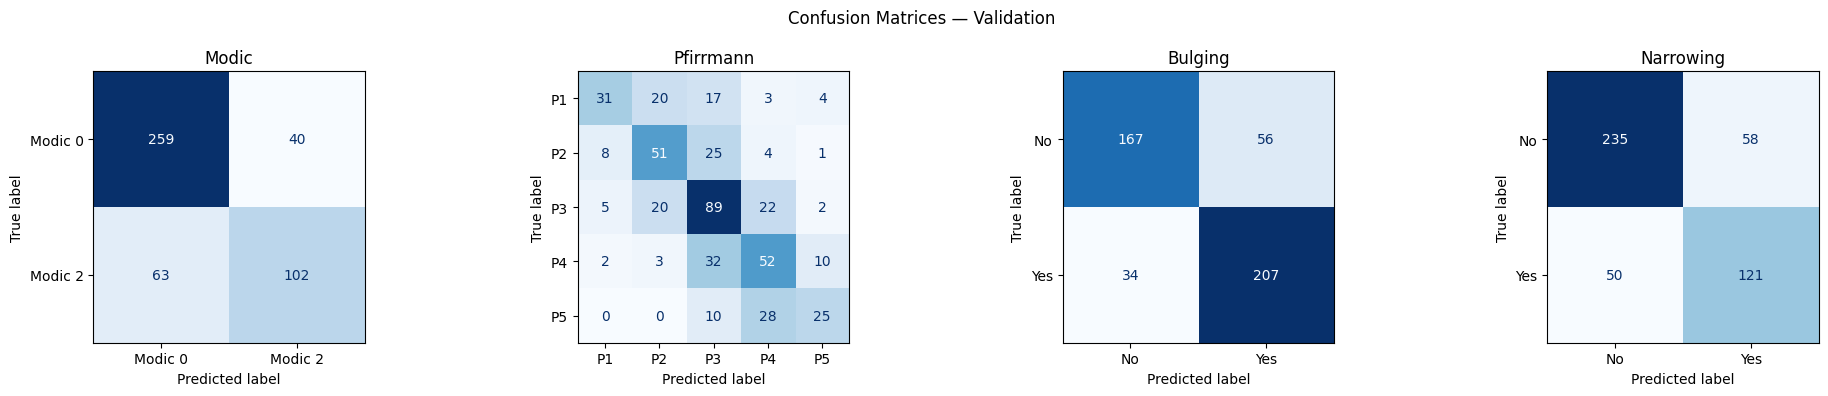

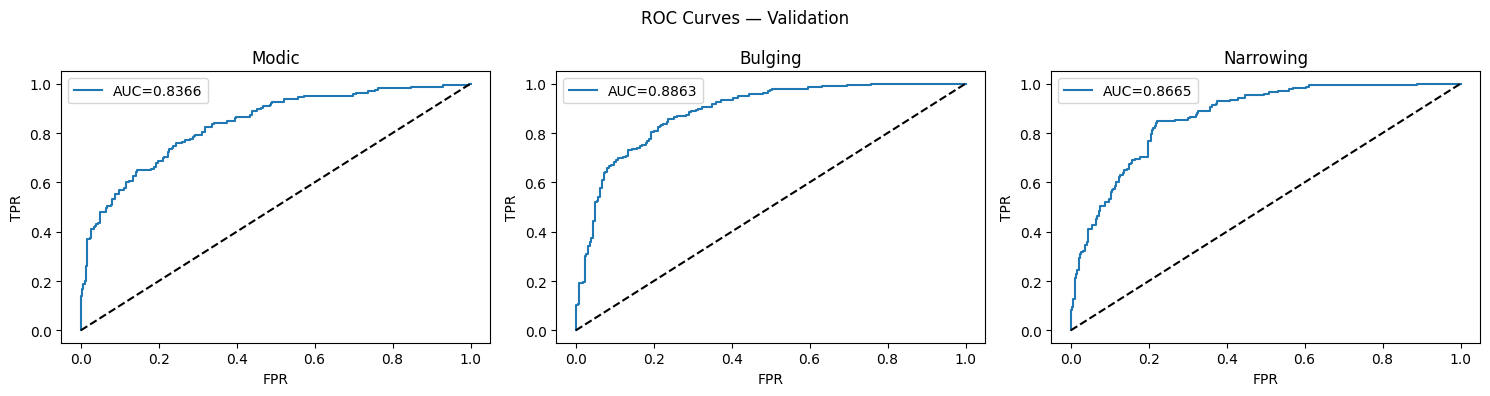


MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.7994    0.9064    0.8495       299
     Modic 2     0.7778    0.5904    0.6712       166

    accuracy                         0.7935       465
   macro avg     0.7886    0.7484    0.7604       465
weighted avg     0.7917    0.7935    0.7859       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.4923    0.4571    0.4741        70
          P2     0.4808    0.4348    0.4566       115
          P3     0.4943    0.6324    0.5548       136
          P4     0.5000    0.4000    0.4444        90
          P5     0.6200    0.5741    0.5962        54

    accuracy                         0.5054       465
   macro avg     0.5175    0.4997    0.5052       465
weighted avg     0.5063    0.5054    0.5018       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.8147    0.7941    0.8043       238
         Yes     0.7897    

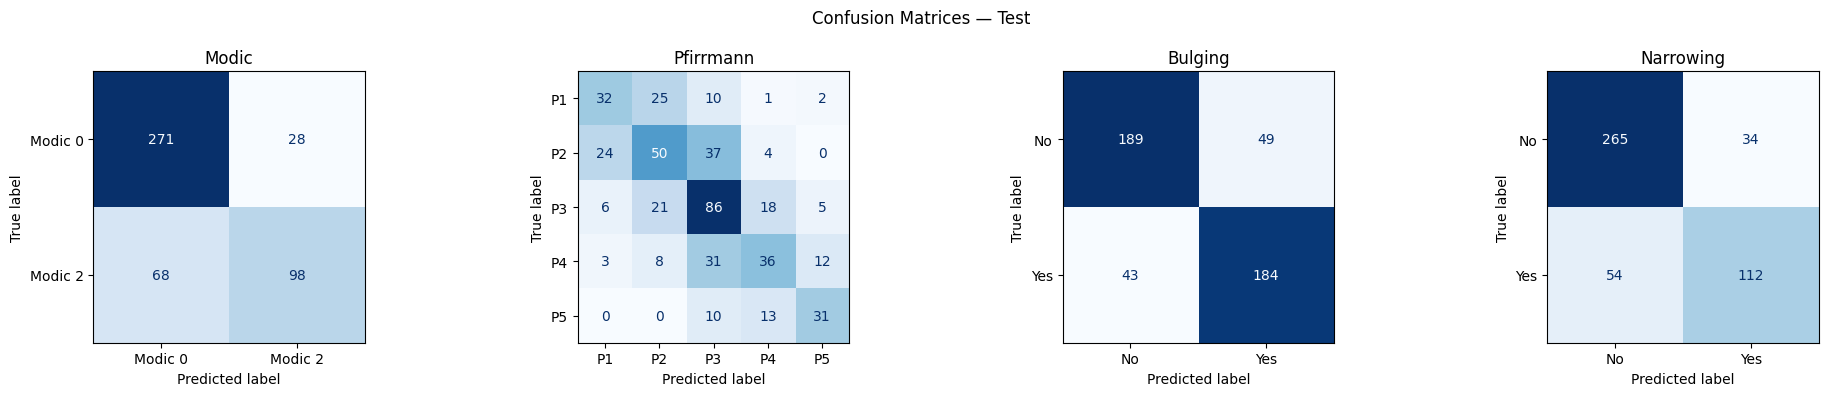

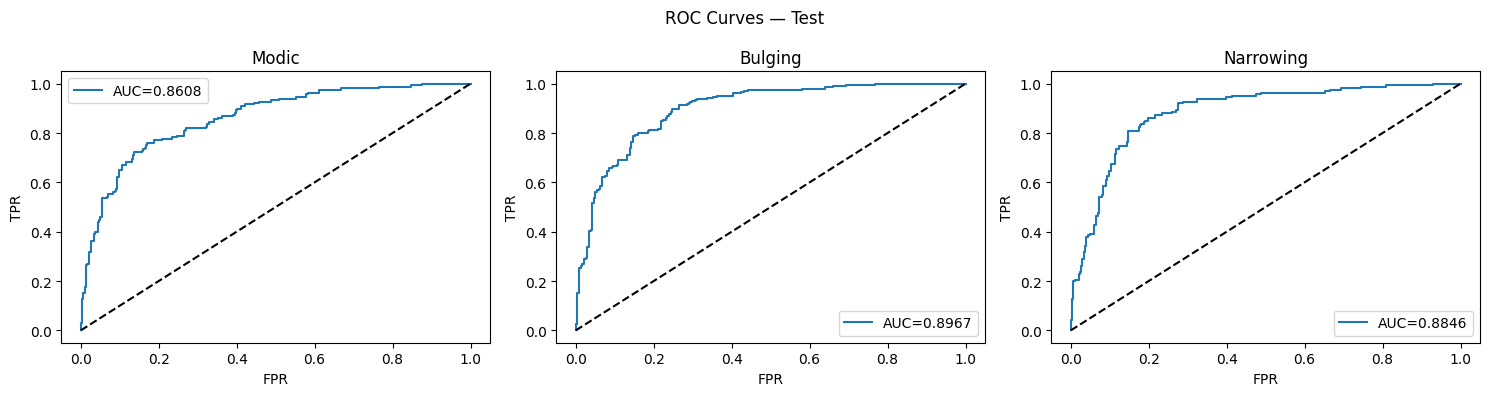

In [8]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("GPU:", torch.cuda.get_device_name(0))

DATA_DIR     = "/kaggle/input/datasets/prasanth6/lumbar-spine-disc/disc_samples_final_v2"
TARGET_SHAPE = (32, 128, 128)
BATCH_SIZE   = 4
EPOCHS       = 25
LR           = 1e-4
PATIENCE     = 5

# =========================================================
# DATASET — resize + z-score
# =========================================================
class DiscDataset(Dataset):
    def __init__(self, files, target_shape=TARGET_SHAPE):
        self.target_shape = target_shape
        self.files = []
        skipped = 0
        for f in files:
            try:
                data  = np.load(f, allow_pickle=True)
                modic = int(data["labels"].item()["modic"])
                if modic in [0, 2]:
                    self.files.append(f)
                else:
                    skipped += 1
            except Exception as e:
                print(f"  [WARN] {f}: {e}")
                skipped += 1
        print(f"  Loaded {len(self.files)} samples | skipped {skipped}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data  = np.load(self.files[idx], allow_pickle=True)
        image = torch.tensor(data["image"],
                             dtype=torch.float32).unsqueeze(0)
        # Resize to fixed shape
        image = F.interpolate(
            image.unsqueeze(0), size=self.target_shape,
            mode="trilinear", align_corners=False
        ).squeeze(0)
        # Z-score normalise per volume
        image = (image - image.mean()) / (image.std() + 1e-6)

        labels    = data["labels"].item()
        modic_raw = int(labels["modic"])
        pfirrmann = max(0, min(int(labels["pfirrmann"]) - 1, 4))

        return image, {
            "modic":     torch.tensor(
                0 if modic_raw == 0 else 1, dtype=torch.long),
            "pfirrmann": torch.tensor(pfirrmann, dtype=torch.long),
            "bulging":   torch.tensor(
                float(labels["bulging"]), dtype=torch.float32),
            "narrowing": torch.tensor(
                float(labels["narrowing"]), dtype=torch.float32),
        }


# =========================================================
# STRATIFIED SPLIT — filter before splitting
# =========================================================
all_files = sorted([
    os.path.join(DATA_DIR, f)
    for f in os.listdir(DATA_DIR) if f.endswith(".npz")
])
print(f"Total .npz files: {len(all_files)}")

labels_for_split, valid_files = [], []
for f in all_files:
    try:
        d = np.load(f, allow_pickle=True)
        m = int(d["labels"].item()["modic"])
        if m in [0, 2]:
            labels_for_split.append(m)
            valid_files.append(f)
    except Exception:
        pass

print(f"Valid files (modic 0 or 2): {len(valid_files)}")

train_files, temp_files, _, temp_labels = train_test_split(
    valid_files, labels_for_split,
    test_size=0.30, stratify=labels_for_split, random_state=42
)
val_files, test_files = train_test_split(
    temp_files, test_size=0.50,
    stratify=temp_labels, random_state=42
)
print(f"\nSplit → Train:{len(train_files)} Val:{len(val_files)} Test:{len(test_files)}")

print("\nBuilding Train dataset:")
train_ds = DiscDataset(train_files)
print("Building Val dataset:")
val_ds   = DiscDataset(val_files)
print("Building Test dataset:")
test_ds  = DiscDataset(test_files)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)


# =========================================================
# RESNET 3D
# =========================================================
class BasicBlock3D(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv3d(in_ch, out_ch, 3,
                               stride=stride, padding=1, bias=False)
        self.bn1   = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv3d(out_ch, out_ch, 3,
                               padding=1, bias=False)
        self.bn2   = nn.GroupNorm(8, out_ch)
        self.relu  = nn.ReLU(inplace=True)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_ch, out_ch, 1,
                          stride=stride, bias=False),
                nn.GroupNorm(8, out_ch)
            )

    def forward(self, x):
        out  = self.relu(self.bn1(self.conv1(x)))
        out  = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return self.relu(out)


class ResNet3D(nn.Module):
    def __init__(self):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv3d(1, 64, 7, stride=2, padding=3, bias=False),
            nn.GroupNorm(8, 64),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(3, stride=2, padding=1)
        )

        self.layer1 = BasicBlock3D(64,  128)
        self.layer2 = BasicBlock3D(128, 256, stride=2)
        self.layer3 = BasicBlock3D(256, 512, stride=2)

        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)

        self.head_modic = nn.Sequential(
            nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, 2))
        self.head_pfirrmann = nn.Sequential(
            nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, 5))
        self.head_bulging = nn.Sequential(
            nn.Linear(512, 64),  nn.ReLU(), nn.Linear(64, 1))
        self.head_narrowing = nn.Sequential(
            nn.Linear(512, 64),  nn.ReLU(), nn.Linear(64, 1))

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.dropout(self.pool(x).flatten(1))

        return {
            "modic":     self.head_modic(x),
            "pfirrmann": self.head_pfirrmann(x),
            "bulging":   self.head_bulging(x).squeeze(1),
            "narrowing": self.head_narrowing(x).squeeze(1),
        }


# =========================================================
# LOSS
# =========================================================
ce  = nn.CrossEntropyLoss()
bce = nn.BCEWithLogitsLoss()

def multitask_loss(out, tgt):
    return (
        ce( out["modic"],     tgt["modic"])     +
        ce( out["pfirrmann"], tgt["pfirrmann"]) +
        bce(out["bulging"],   tgt["bulging"])   +
        bce(out["narrowing"], tgt["narrowing"])
    )


# =========================================================
# TRAIN / EVAL
# =========================================================
model     = ResNet3D().to(device)
optimizer = torch.optim.AdamW(model.parameters(),
                               lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS)
scaler    = GradScaler(enabled=True)

n_params = sum(p.numel() for p in model.parameters()
               if p.requires_grad)
print(f"\nResNet3D params: {n_params:,}")


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total = 0.0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for img, tgt in loader:
            img = img.to(device)
            tgt = {k: v.to(device) for k, v in tgt.items()}
            if train:
                optimizer.zero_grad()
            with autocast(device.type):
                out  = model(img)
                loss = multitask_loss(out, tgt)
            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total += loss.item()
    return total / max(len(loader), 1)


train_losses, val_losses = [], []
best_val = np.inf
counter  = 0

for epoch in range(EPOCHS):
    tr = run_epoch(train_loader, train=True)
    vl = run_epoch(val_loader,   train=False)
    scheduler.step()
    train_losses.append(tr)
    val_losses.append(vl)
    print(f"Epoch {epoch+1:02d}/{EPOCHS}  |  "
          f"Train {tr:.4f}  |  Val {vl:.4f}")
    if vl < best_val:
        best_val = vl; counter = 0
        torch.save(model.state_dict(), "best_resnet3d.pth")
        print("  ✔ Saved best model")
    else:
        counter += 1
        if counter >= PATIENCE:
            print("Early stopping."); break

plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train")
plt.plot(val_losses,   label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("ResNet3D — Loss")
plt.legend(); plt.tight_layout(); plt.show()


# =========================================================
# EVALUATION
# =========================================================
def evaluate(loader, split_name="Test"):
    model.load_state_dict(
        torch.load("best_resnet3d.pth", map_location=device))
    model.eval()

    preds = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}
    probs = {k: [] for k in ["modic", "bulging", "narrowing"]}
    gts   = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}

    with torch.no_grad():
        for img, tgt in loader:
            img = img.to(device)
            out = model(img)

            p_m = torch.softmax(out["modic"], 1)[:, 1]
            probs["modic"].extend(p_m.cpu().numpy())
            preds["modic"].extend(
                out["modic"].argmax(1).cpu().numpy())
            gts["modic"].extend(tgt["modic"].numpy())

            preds["pfirrmann"].extend(
                out["pfirrmann"].argmax(1).cpu().numpy())
            gts["pfirrmann"].extend(tgt["pfirrmann"].numpy())

            p_b = torch.sigmoid(out["bulging"])
            probs["bulging"].extend(p_b.cpu().numpy())
            preds["bulging"].extend(
                (p_b > 0.5).long().cpu().numpy())
            gts["bulging"].extend(
                tgt["bulging"].long().numpy())

            p_n = torch.sigmoid(out["narrowing"])
            probs["narrowing"].extend(p_n.cpu().numpy())
            preds["narrowing"].extend(
                (p_n > 0.5).long().cpu().numpy())
            gts["narrowing"].extend(
                tgt["narrowing"].long().numpy())

    task_labels = {
        "modic":     (["Modic 0", "Modic 2"],
                      f"\nMODIC — {split_name}"),
        "pfirrmann": ([f"P{i+1}" for i in range(5)],
                      f"\nPFIRRMANN — {split_name}"),
        "bulging":   (["No", "Yes"],
                      f"\nBULGING — {split_name}"),
        "narrowing": (["No", "Yes"],
                      f"\nNARROWING — {split_name}"),
    }
    for task, (names, title) in task_labels.items():
        print(title)
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i < len(names)]
        print(classification_report(
            gts[task], preds[task], labels=present,
            target_names=used, digits=4, zero_division=0))

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    fig.suptitle(f"Confusion Matrices — {split_name}")
    for ax, (task, (names, _)) in zip(axes, task_labels.items()):
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i < len(names)]
        ConfusionMatrixDisplay(
            confusion_matrix(gts[task], preds[task]),
            display_labels=used
        ).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(task.capitalize())
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"ROC Curves — {split_name}")
    for ax, task in zip(axes, ["modic", "bulging", "narrowing"]):
        gt_arr   = np.array(gts[task])
        prob_arr = np.array(probs[task])
        if len(np.unique(gt_arr)) < 2:
            ax.set_title(f"{task} (1 class)"); continue
        fpr, tpr, _ = roc_curve(gt_arr, prob_arr)
        ax.plot(fpr, tpr, label=f"AUC={auc(fpr, tpr):.4f}")
        ax.plot([0, 1], [0, 1], "k--")
        ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
        ax.set_title(task.capitalize()); ax.legend()
    plt.tight_layout(); plt.show()


evaluate(val_loader,  split_name="Validation")
evaluate(test_loader, split_name="Test")

**DENSENET 3D**

Using device: cuda
GPU: Tesla P100-PCIE-16GB
Total .npz files: 3119
Valid files (modic 0 or 2): 3095

Split → Train:2166 Val:464 Test:465

Building Train dataset:
  Loaded 2166 samples | skipped 0
Building Val dataset:
  Loaded 464 samples | skipped 0
Building Test dataset:
  Loaded 465 samples | skipped 0

DenseNet3D params: 1,115,273
Epoch 01/25  |  Train 3.5999  |  Val 3.5710
  ✔ Saved best model
Epoch 02/25  |  Train 3.5527  |  Val 3.4336
  ✔ Saved best model
Epoch 03/25  |  Train 3.2917  |  Val 3.0937
  ✔ Saved best model
Epoch 04/25  |  Train 3.1126  |  Val 3.0188
  ✔ Saved best model
Epoch 05/25  |  Train 2.9952  |  Val 3.0524
Epoch 06/25  |  Train 2.9183  |  Val 2.9939
  ✔ Saved best model
Epoch 07/25  |  Train 2.8455  |  Val 2.8928
  ✔ Saved best model
Epoch 08/25  |  Train 2.7822  |  Val 2.8769
  ✔ Saved best model
Epoch 09/25  |  Train 2.7623  |  Val 2.8615
  ✔ Saved best model
Epoch 10/25  |  Train 2.6890  |  Val 2.9123
Epoch 11/25  |  Train 2.6280  |  Val 2.8926
Epoch 12/2

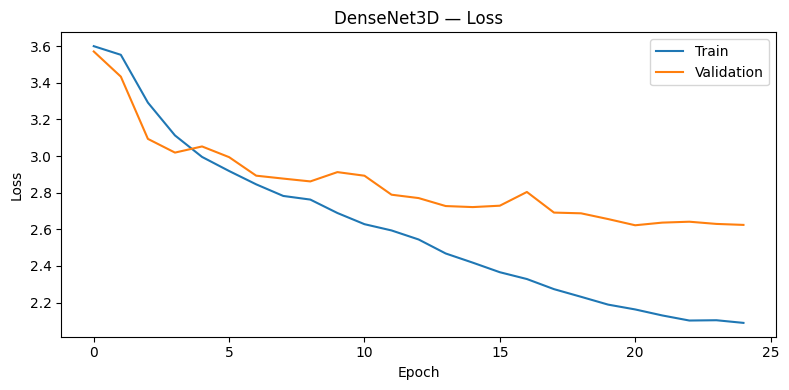


MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.7733    0.8328    0.8019       299
     Modic 2     0.6479    0.5576    0.5993       165

    accuracy                         0.7349       464
   macro avg     0.7106    0.6952    0.7006       464
weighted avg     0.7287    0.7349    0.7299       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.5600    0.3733    0.4480        75
          P2     0.5000    0.4944    0.4972        89
          P3     0.5000    0.5725    0.5338       138
          P4     0.4184    0.4141    0.4162        99
          P5     0.5429    0.6032    0.5714        63

    accuracy                         0.4957       464
   macro avg     0.5042    0.4915    0.4933       464
weighted avg     0.4981    0.4957    0.4929       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.8469    0.7444    0.7924       223
         

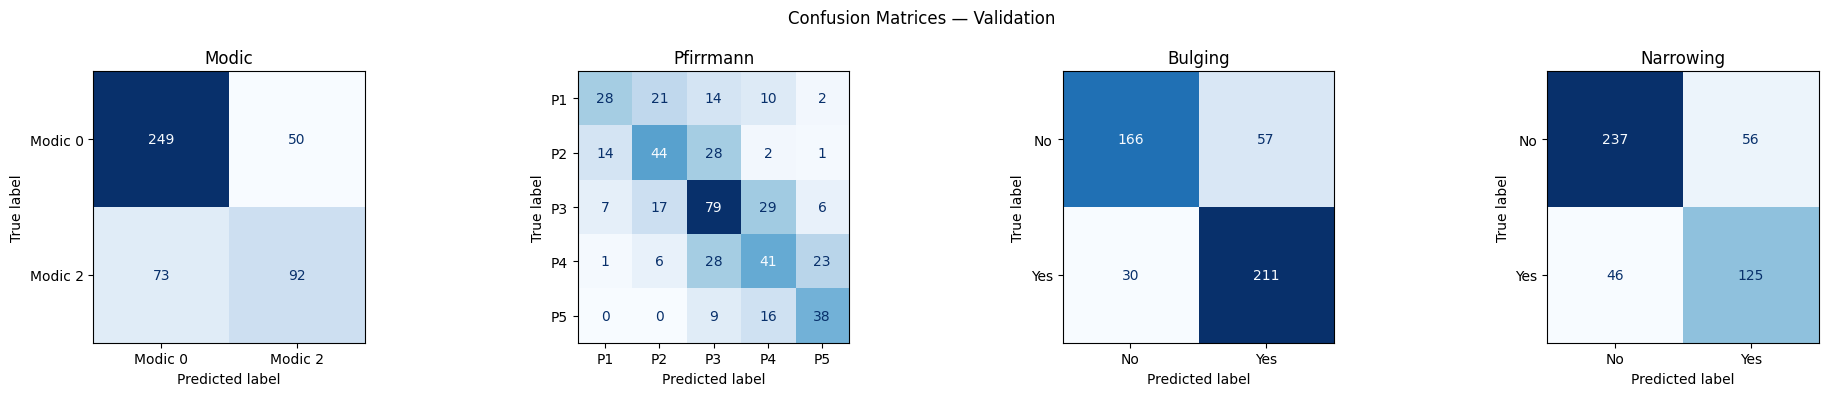

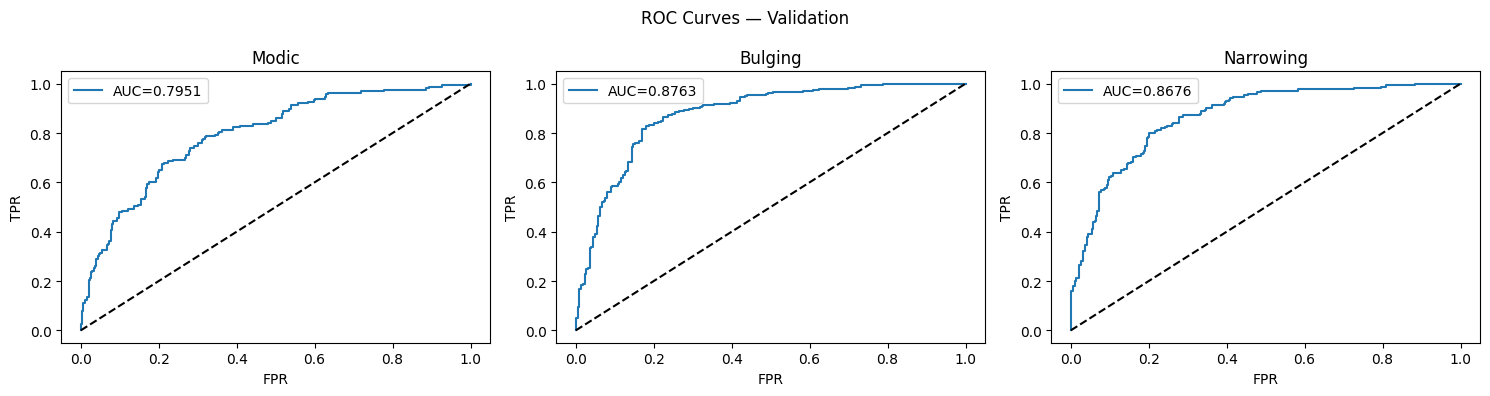


MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.7822    0.8528    0.8160       299
     Modic 2     0.6835    0.5723    0.6230       166

    accuracy                         0.7527       465
   macro avg     0.7328    0.7126    0.7195       465
weighted avg     0.7470    0.7527    0.7471       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.5593    0.4714    0.5116        70
          P2     0.4592    0.3913    0.4225       115
          P3     0.4423    0.5074    0.4726       136
          P4     0.3889    0.3889    0.3889        90
          P5     0.5000    0.5741    0.5345        54

    accuracy                         0.4581       465
   macro avg     0.4699    0.4666    0.4660       465
weighted avg     0.4605    0.4581    0.4571       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.8502    0.7395    0.7910       238
         Yes     0.7597    

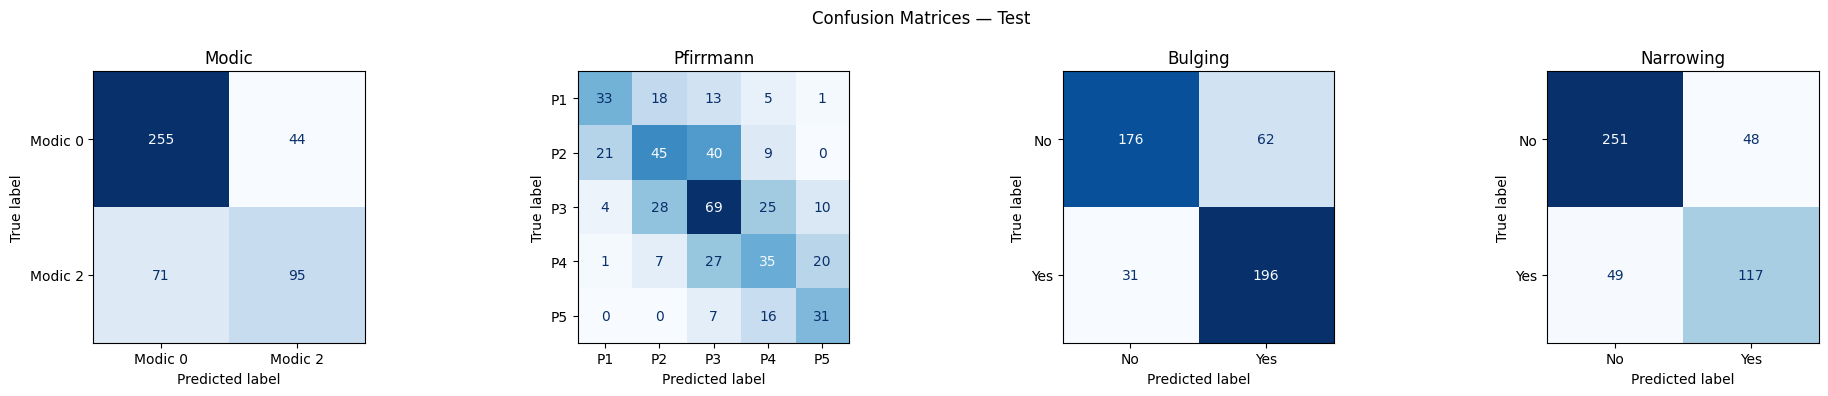

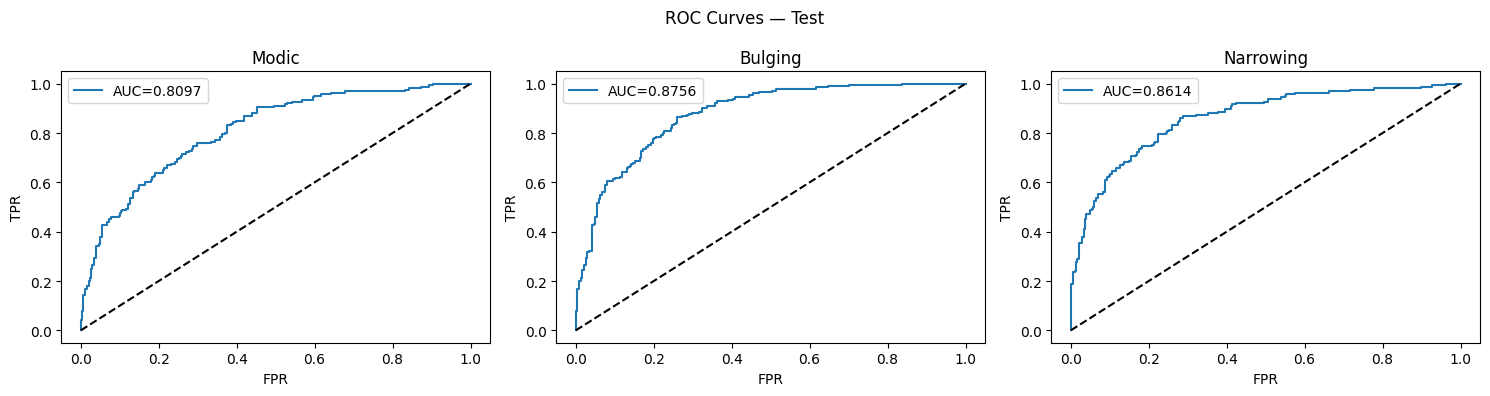

In [9]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("GPU:", torch.cuda.get_device_name(0))

DATA_DIR     = "/kaggle/input/datasets/prasanth6/lumbar-spine-disc/disc_samples_final_v2"
TARGET_SHAPE = (32, 128, 128)
BATCH_SIZE   = 4
EPOCHS       = 25
LR           = 1e-4
PATIENCE     = 5

# =========================================================
# DATASET — resize + z-score, identical to best model
# =========================================================
class DiscDataset(Dataset):
    def __init__(self, files, target_shape=TARGET_SHAPE):
        self.target_shape = target_shape
        self.files = []
        skipped = 0
        for f in files:
            try:
                data  = np.load(f, allow_pickle=True)
                modic = int(data["labels"].item()["modic"])
                if modic in [0, 2]:
                    self.files.append(f)
                else:
                    skipped += 1
            except Exception as e:
                print(f"  [WARN] {f}: {e}")
                skipped += 1
        print(f"  Loaded {len(self.files)} samples | skipped {skipped}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data  = np.load(self.files[idx], allow_pickle=True)
        image = torch.tensor(data["image"],
                             dtype=torch.float32).unsqueeze(0)
        # Resize to fixed shape
        image = F.interpolate(
            image.unsqueeze(0), size=self.target_shape,
            mode="trilinear", align_corners=False
        ).squeeze(0)
        # Z-score normalise per volume
        image = (image - image.mean()) / (image.std() + 1e-6)

        labels    = data["labels"].item()
        modic_raw = int(labels["modic"])
        pfirrmann = max(0, min(int(labels["pfirrmann"]) - 1, 4))

        return image, {
            "modic":     torch.tensor(
                0 if modic_raw == 0 else 1, dtype=torch.long),
            "pfirrmann": torch.tensor(pfirrmann, dtype=torch.long),
            "bulging":   torch.tensor(
                float(labels["bulging"]), dtype=torch.float32),
            "narrowing": torch.tensor(
                float(labels["narrowing"]), dtype=torch.float32),
        }


# =========================================================
# STRATIFIED SPLIT — filter before splitting
# =========================================================
all_files = sorted([
    os.path.join(DATA_DIR, f)
    for f in os.listdir(DATA_DIR) if f.endswith(".npz")
])
print(f"Total .npz files: {len(all_files)}")

labels_for_split, valid_files = [], []
for f in all_files:
    try:
        d = np.load(f, allow_pickle=True)
        m = int(d["labels"].item()["modic"])
        if m in [0, 2]:
            labels_for_split.append(m)
            valid_files.append(f)
    except Exception:
        pass

print(f"Valid files (modic 0 or 2): {len(valid_files)}")

train_files, temp_files, _, temp_labels = train_test_split(
    valid_files, labels_for_split,
    test_size=0.30, stratify=labels_for_split, random_state=42
)
val_files, test_files = train_test_split(
    temp_files, test_size=0.50,
    stratify=temp_labels, random_state=42
)
print(f"\nSplit → Train:{len(train_files)} Val:{len(val_files)} Test:{len(test_files)}")

print("\nBuilding Train dataset:")
train_ds = DiscDataset(train_files)
print("Building Val dataset:")
val_ds   = DiscDataset(val_files)
print("Building Test dataset:")
test_ds  = DiscDataset(test_files)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)


# =========================================================
# DENSENET 3D
# =========================================================
class DenseLayer3D(nn.Module):
    def __init__(self, in_ch, growth_rate):
        super().__init__()
        self.layer = nn.Sequential(
            nn.GroupNorm(8, in_ch),
            nn.ReLU(inplace=True),
            nn.Conv3d(in_ch, growth_rate, 3, padding=1,
                      bias=False)
        )
    def forward(self, x):
        return torch.cat([x, self.layer(x)], 1)


class DenseBlock3D(nn.Module):
    def __init__(self, in_ch, growth_rate, num_layers):
        super().__init__()
        layers = []
        ch = in_ch
        for _ in range(num_layers):
            layers.append(DenseLayer3D(ch, growth_rate))
            ch += growth_rate
        self.block = nn.Sequential(*layers)
        self.out_ch = ch
    def forward(self, x):
        return self.block(x)


class Transition3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.trans = nn.Sequential(
            nn.GroupNorm(8, in_ch),
            nn.ReLU(inplace=True),
            nn.Conv3d(in_ch, out_ch, 1, bias=False),
            nn.AvgPool3d(2, stride=2)   # spatial downsampling
        )
    def forward(self, x):
        return self.trans(x)


class DenseNet3D(nn.Module):
    def __init__(self, growth_rate=16):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv3d(1, 64, 7, stride=2, padding=3,
                      bias=False),
            nn.GroupNorm(8, 64),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(3, stride=2, padding=1)
        )
        self.db1 = DenseBlock3D(64,  growth_rate, 4)
        self.tr1 = Transition3D(self.db1.out_ch, 128)
        self.db2 = DenseBlock3D(128, growth_rate, 4)
        self.tr2 = Transition3D(self.db2.out_ch, 256)
        self.db3 = DenseBlock3D(256, growth_rate, 4)

        self.pool = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)

        feat = self.db3.out_ch
        self.head_modic     = nn.Sequential(
            nn.Linear(feat, 128), nn.ReLU(), nn.Linear(128, 2))
        self.head_pfirrmann = nn.Sequential(
            nn.Linear(feat, 128), nn.ReLU(), nn.Linear(128, 5))
        self.head_bulging   = nn.Sequential(
            nn.Linear(feat, 64),  nn.ReLU(), nn.Linear(64, 1))
        self.head_narrowing = nn.Sequential(
            nn.Linear(feat, 64),  nn.ReLU(), nn.Linear(64, 1))

    def forward(self, x):
        x = self.stem(x)
        x = self.tr1(self.db1(x))
        x = self.tr2(self.db2(x))
        x = self.db3(x)
        x = self.dropout(self.pool(x).flatten(1))
        return {
            "modic":     self.head_modic(x),
            "pfirrmann": self.head_pfirrmann(x),
            "bulging":   self.head_bulging(x).squeeze(1),
            "narrowing": self.head_narrowing(x).squeeze(1),
        }


# =========================================================
# LOSS — identical to best model
# =========================================================
ce  = nn.CrossEntropyLoss()
bce = nn.BCEWithLogitsLoss()

def multitask_loss(out, tgt):
    return (
        ce( out["modic"],     tgt["modic"])      +
        ce( out["pfirrmann"], tgt["pfirrmann"])  +
        bce(out["bulging"],   tgt["bulging"])    +
        bce(out["narrowing"], tgt["narrowing"])
    )


# =========================================================
# TRAIN / EVAL
# =========================================================
model     = DenseNet3D().to(device)
optimizer = torch.optim.AdamW(model.parameters(),
                               lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS)
scaler    = GradScaler(enabled=True)

n_params = sum(p.numel() for p in model.parameters()
               if p.requires_grad)
print(f"\nDenseNet3D params: {n_params:,}")


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total = 0.0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for img, tgt in loader:
            img = img.to(device)
            tgt = {k: v.to(device) for k, v in tgt.items()}
            if train:
                optimizer.zero_grad()
            with autocast(device.type):
                out  = model(img)
                loss = multitask_loss(out, tgt)
            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total += loss.item()
    return total / max(len(loader), 1)


train_losses, val_losses = [], []
best_val = np.inf
counter  = 0

for epoch in range(EPOCHS):
    tr = run_epoch(train_loader, train=True)
    vl = run_epoch(val_loader,   train=False)
    scheduler.step()
    train_losses.append(tr)
    val_losses.append(vl)
    print(f"Epoch {epoch+1:02d}/{EPOCHS}  |  "
          f"Train {tr:.4f}  |  Val {vl:.4f}")
    if vl < best_val:
        best_val = vl; counter = 0
        torch.save(model.state_dict(), "best_densenet3d.pth")
        print("  ✔ Saved best model")
    else:
        counter += 1
        if counter >= PATIENCE:
            print("Early stopping."); break

plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train")
plt.plot(val_losses,   label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("DenseNet3D — Loss")
plt.legend(); plt.tight_layout(); plt.show()


# =========================================================
# EVALUATION
# =========================================================
def evaluate(loader, split_name="Test"):
    model.load_state_dict(
        torch.load("best_densenet3d.pth", map_location=device))
    model.eval()

    preds = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}
    probs = {k: [] for k in ["modic", "bulging", "narrowing"]}
    gts   = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}

    with torch.no_grad():
        for img, tgt in loader:
            img = img.to(device)
            out = model(img)
            p_m = torch.softmax(out["modic"], 1)[:, 1]
            probs["modic"].extend(p_m.cpu().numpy())
            preds["modic"].extend(
                out["modic"].argmax(1).cpu().numpy())
            gts["modic"].extend(tgt["modic"].numpy())
            preds["pfirrmann"].extend(
                out["pfirrmann"].argmax(1).cpu().numpy())
            gts["pfirrmann"].extend(tgt["pfirrmann"].numpy())
            p_b = torch.sigmoid(out["bulging"])
            probs["bulging"].extend(p_b.cpu().numpy())
            preds["bulging"].extend(
                (p_b > 0.5).long().cpu().numpy())
            gts["bulging"].extend(
                tgt["bulging"].long().numpy())
            p_n = torch.sigmoid(out["narrowing"])
            probs["narrowing"].extend(p_n.cpu().numpy())
            preds["narrowing"].extend(
                (p_n > 0.5).long().cpu().numpy())
            gts["narrowing"].extend(
                tgt["narrowing"].long().numpy())

    task_labels = {
        "modic":    (["Modic 0", "Modic 2"],
                     f"\nMODIC — {split_name}"),
        "pfirrmann":([f"P{i+1}" for i in range(5)],
                     f"\nPFIRRMANN — {split_name}"),
        "bulging":  (["No", "Yes"],
                     f"\nBULGING — {split_name}"),
        "narrowing":(["No", "Yes"],
                     f"\nNARROWING — {split_name}"),
    }
    for task, (names, title) in task_labels.items():
        print(title)
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i < len(names)]
        print(classification_report(
            gts[task], preds[task], labels=present,
            target_names=used, digits=4, zero_division=0))

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    fig.suptitle(f"Confusion Matrices — {split_name}")
    for ax, (task, (names, _)) in zip(axes, task_labels.items()):
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i < len(names)]
        ConfusionMatrixDisplay(
            confusion_matrix(gts[task], preds[task]),
            display_labels=used
        ).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(task.capitalize())
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"ROC Curves — {split_name}")
    for ax, task in zip(axes, ["modic", "bulging", "narrowing"]):
        gt_arr   = np.array(gts[task])
        prob_arr = np.array(probs[task])
        if len(np.unique(gt_arr)) < 2:
            ax.set_title(f"{task} (1 class)"); continue
        fpr, tpr, _ = roc_curve(gt_arr, prob_arr)
        ax.plot(fpr, tpr, label=f"AUC={auc(fpr,tpr):.4f}")
        ax.plot([0, 1], [0, 1], "k--")
        ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
        ax.set_title(task.capitalize()); ax.legend()
    plt.tight_layout(); plt.show()


evaluate(val_loader,  split_name="Validation")
evaluate(test_loader, split_name="Test")

**INCEPTION 3D**

Using device: cuda
GPU: Tesla P100-PCIE-16GB
Total .npz files: 3119
Valid files (modic 0 or 2): 3095

Split → Train:2166 Val:464 Test:465

Building Train dataset:
  Loaded 2166 samples | skipped 0
Building Val dataset:
  Loaded 464 samples | skipped 0
Building Test dataset:
  Loaded 465 samples | skipped 0

Inception3D params: 4,784,841
Epoch 01/25  |  Train 3.5664  |  Val 3.4557
  ✔ Saved best model
Epoch 02/25  |  Train 3.4340  |  Val 3.3924
  ✔ Saved best model
Epoch 03/25  |  Train 3.3144  |  Val 3.2232
  ✔ Saved best model
Epoch 04/25  |  Train 3.1447  |  Val 3.1222
  ✔ Saved best model
Epoch 05/25  |  Train 3.0610  |  Val 3.1086
  ✔ Saved best model
Epoch 06/25  |  Train 2.9832  |  Val 3.1091
Epoch 07/25  |  Train 2.8751  |  Val 3.0179
  ✔ Saved best model
Epoch 08/25  |  Train 2.7739  |  Val 3.0244
Epoch 09/25  |  Train 2.7109  |  Val 2.9309
  ✔ Saved best model
Epoch 10/25  |  Train 2.6118  |  Val 2.9503
Epoch 11/25  |  Train 2.4878  |  Val 2.9427
Epoch 12/25  |  Train 2.3861  

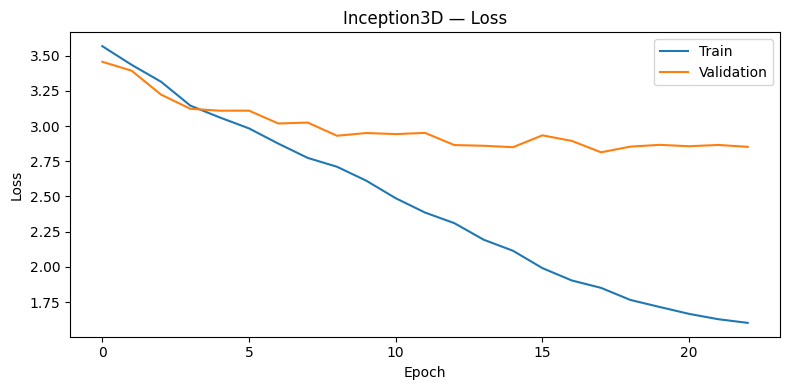


MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.7866    0.8629    0.8230       299
     Modic 2     0.6985    0.5758    0.6312       165

    accuracy                         0.7608       464
   macro avg     0.7426    0.7193    0.7271       464
weighted avg     0.7553    0.7608    0.7548       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.5714    0.2667    0.3636        75
          P2     0.4038    0.4719    0.4352        89
          P3     0.4171    0.5652    0.4800       138
          P4     0.4674    0.4343    0.4503        99
          P5     0.6087    0.4444    0.5138        63

    accuracy                         0.4547       464
   macro avg     0.4937    0.4365    0.4486       464
weighted avg     0.4763    0.4547    0.4508       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.8317    0.7758    0.8028       223
         

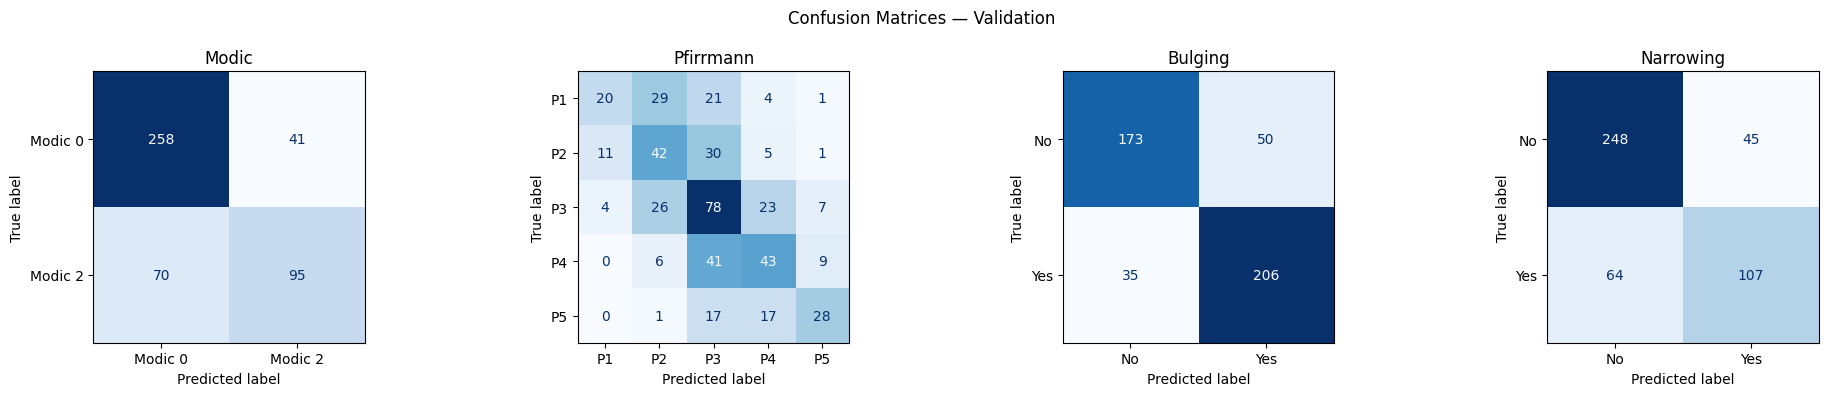

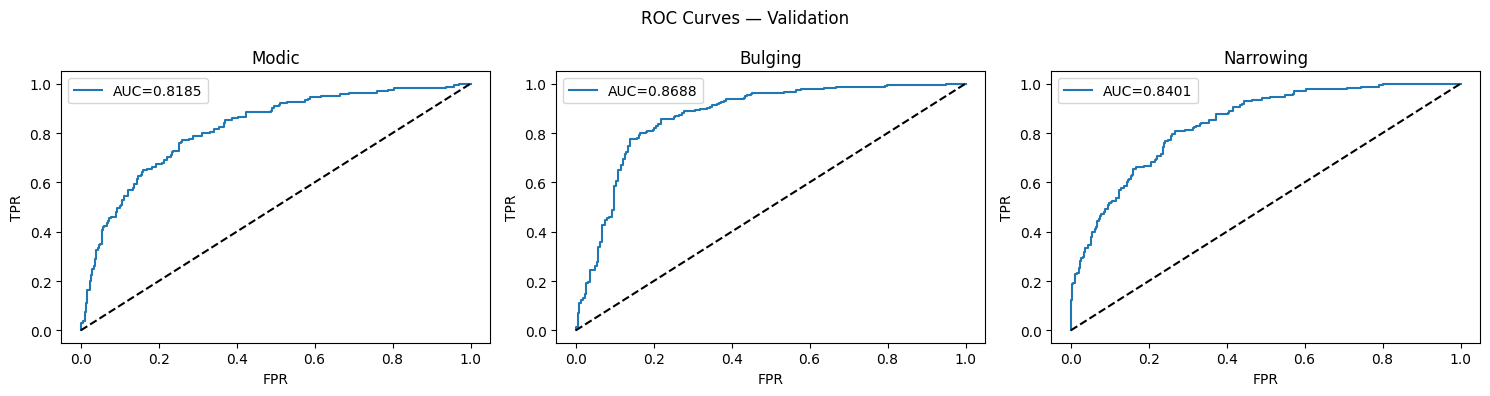


MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.7662    0.9097    0.8318       299
     Modic 2     0.7545    0.5000    0.6014       166

    accuracy                         0.7634       465
   macro avg     0.7604    0.7048    0.7166       465
weighted avg     0.7620    0.7634    0.7496       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.4906    0.3714    0.4228        70
          P2     0.4717    0.4348    0.4525       115
          P3     0.4206    0.6618    0.5143       136
          P4     0.4386    0.2778    0.3401        90
          P5     0.6857    0.4444    0.5393        54

    accuracy                         0.4624       465
   macro avg     0.5014    0.4380    0.4538       465
weighted avg     0.4780    0.4624    0.4544       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.8112    0.7941    0.8025       238
         Yes     0.7888    

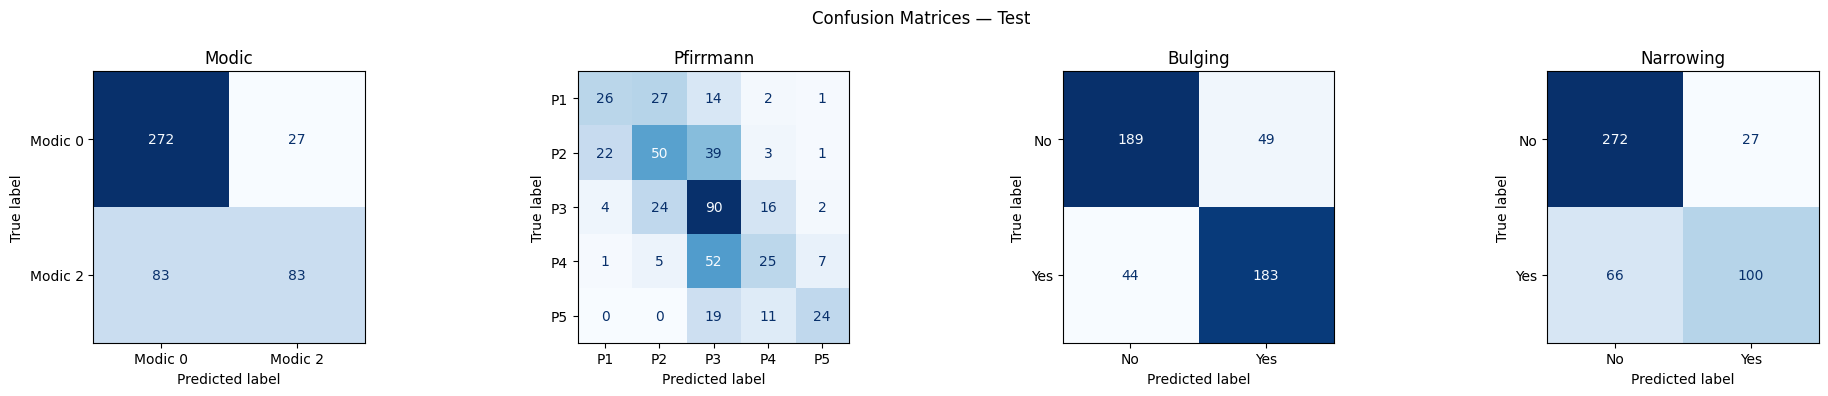

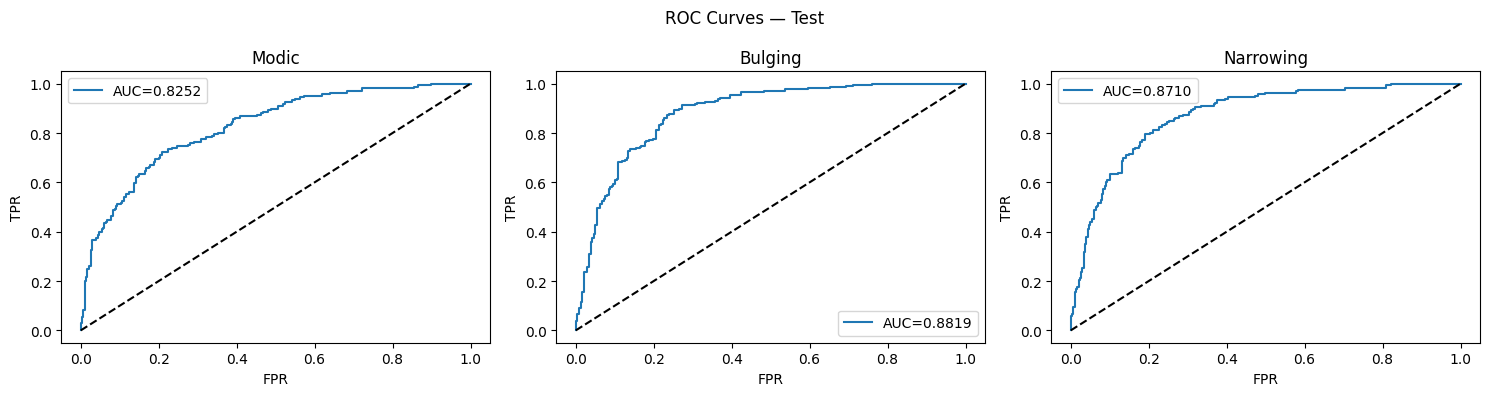

In [10]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("GPU:", torch.cuda.get_device_name(0))

DATA_DIR     = "/kaggle/input/datasets/prasanth6/lumbar-spine-disc/disc_samples_final_v2"
TARGET_SHAPE = (32, 128, 128)
BATCH_SIZE   = 4
EPOCHS       = 25
LR           = 1e-4
PATIENCE     = 5

# =========================================================
# DATASET — resize + z-score
# =========================================================
class DiscDataset(Dataset):
    def __init__(self, files, target_shape=TARGET_SHAPE):
        self.target_shape = target_shape
        self.files = []
        skipped = 0
        for f in files:
            try:
                data  = np.load(f, allow_pickle=True)
                modic = int(data["labels"].item()["modic"])
                if modic in [0, 2]:
                    self.files.append(f)
                else:
                    skipped += 1
            except Exception as e:
                print(f"  [WARN] {f}: {e}")
                skipped += 1
        print(f"  Loaded {len(self.files)} samples | skipped {skipped}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data  = np.load(self.files[idx], allow_pickle=True)
        image = torch.tensor(data["image"],
                             dtype=torch.float32).unsqueeze(0)
        # Resize to fixed shape
        image = F.interpolate(
            image.unsqueeze(0), size=self.target_shape,
            mode="trilinear", align_corners=False
        ).squeeze(0)
        # Z-score normalise per volume
        image = (image - image.mean()) / (image.std() + 1e-6)

        labels    = data["labels"].item()
        modic_raw = int(labels["modic"])
        pfirrmann = max(0, min(int(labels["pfirrmann"]) - 1, 4))

        return image, {
            "modic":     torch.tensor(
                0 if modic_raw == 0 else 1, dtype=torch.long),
            "pfirrmann": torch.tensor(pfirrmann, dtype=torch.long),
            "bulging":   torch.tensor(
                float(labels["bulging"]), dtype=torch.float32),
            "narrowing": torch.tensor(
                float(labels["narrowing"]), dtype=torch.float32),
        }


# =========================================================
# STRATIFIED SPLIT — filter before splitting
# =========================================================
all_files = sorted([
    os.path.join(DATA_DIR, f)
    for f in os.listdir(DATA_DIR) if f.endswith(".npz")
])
print(f"Total .npz files: {len(all_files)}")

labels_for_split, valid_files = [], []
for f in all_files:
    try:
        d = np.load(f, allow_pickle=True)
        m = int(d["labels"].item()["modic"])
        if m in [0, 2]:
            labels_for_split.append(m)
            valid_files.append(f)
    except Exception:
        pass

print(f"Valid files (modic 0 or 2): {len(valid_files)}")

train_files, temp_files, _, temp_labels = train_test_split(
    valid_files, labels_for_split,
    test_size=0.30, stratify=labels_for_split, random_state=42
)
val_files, test_files = train_test_split(
    temp_files, test_size=0.50,
    stratify=temp_labels, random_state=42
)
print(f"\nSplit → Train:{len(train_files)} Val:{len(val_files)} Test:{len(test_files)}")

print("\nBuilding Train dataset:")
train_ds = DiscDataset(train_files)
print("Building Val dataset:")
val_ds   = DiscDataset(val_files)
print("Building Test dataset:")
test_ds  = DiscDataset(test_files)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)


# =========================================================
# INCEPTION 3D (DISC-SAFE)
# =========================================================
class GN(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.gn = nn.GroupNorm(8, ch)

    def forward(self, x):
        return self.gn(x)


class InceptionBlock3D(nn.Module):
    """
    Three parallel branches (1×1, 3×3, 5×5) concatenated.
    out_ch must be divisible by 3.
    """
    def __init__(self, in_ch, out_ch):
        super().__init__()
        b = out_ch // 3

        self.b1 = nn.Sequential(
            nn.Conv3d(in_ch, b, 1, bias=False),
            GN(b), nn.ReLU(inplace=True)
        )
        self.b3 = nn.Sequential(
            nn.Conv3d(in_ch, b, 1, bias=False),
            GN(b), nn.ReLU(inplace=True),
            nn.Conv3d(b, b, 3, padding=1, bias=False),
            GN(b), nn.ReLU(inplace=True)
        )
        self.b5 = nn.Sequential(
            nn.Conv3d(in_ch, b, 1, bias=False),
            GN(b), nn.ReLU(inplace=True),
            nn.Conv3d(b, b, 5, padding=2, bias=False),
            GN(b), nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x)], dim=1)


class Inception3D(nn.Module):
    def __init__(self):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv3d(1, 64, 7, stride=2, padding=3, bias=False),
            GN(64), nn.ReLU(inplace=True),
            nn.MaxPool3d(3, stride=2, padding=1)
        )

        # Block 1: 64 → 96
        self.inc1 = InceptionBlock3D(64, 96)
        self.down1 = nn.Sequential(
            nn.Conv3d(96, 96, 3, stride=2, padding=1, bias=False),
            GN(96), nn.ReLU(inplace=True)
        )

        # Block 2: 96 → 192
        self.inc2 = InceptionBlock3D(96, 192)
        self.down2 = nn.Sequential(
            nn.Conv3d(192, 192, 3, stride=2, padding=1, bias=False),
            GN(192), nn.ReLU(inplace=True)
        )

        # Block 3: 192 → 384
        self.inc3 = InceptionBlock3D(192, 384)

        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)

        # modic: 2 classes (Modic 0 vs Modic 2)
        self.head_modic = nn.Sequential(
            nn.Linear(384, 128), nn.ReLU(), nn.Linear(128, 2))
        self.head_pfirrmann = nn.Sequential(
            nn.Linear(384, 128), nn.ReLU(), nn.Linear(128, 5))
        self.head_bulging = nn.Sequential(
            nn.Linear(384, 64),  nn.ReLU(), nn.Linear(64, 1))
        self.head_narrowing = nn.Sequential(
            nn.Linear(384, 64),  nn.ReLU(), nn.Linear(64, 1))

    def forward(self, x):
        x = self.stem(x)
        x = self.down1(self.inc1(x))
        x = self.down2(self.inc2(x))
        x = self.inc3(x)
        x = self.dropout(self.pool(x).flatten(1))

        return {
            "modic":     self.head_modic(x),
            "pfirrmann": self.head_pfirrmann(x),
            "bulging":   self.head_bulging(x).squeeze(1),
            "narrowing": self.head_narrowing(x).squeeze(1),
        }


# =========================================================
# LOSS
# =========================================================
ce  = nn.CrossEntropyLoss()
bce = nn.BCEWithLogitsLoss()

def multitask_loss(out, tgt):
    return (
        ce( out["modic"],     tgt["modic"])     +
        ce( out["pfirrmann"], tgt["pfirrmann"]) +
        bce(out["bulging"],   tgt["bulging"])   +
        bce(out["narrowing"], tgt["narrowing"])
    )


# =========================================================
# TRAIN / EVAL
# =========================================================
model     = Inception3D().to(device)
optimizer = torch.optim.AdamW(model.parameters(),
                               lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS)
scaler    = GradScaler(enabled=True)

n_params = sum(p.numel() for p in model.parameters()
               if p.requires_grad)
print(f"\nInception3D params: {n_params:,}")


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total = 0.0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for img, tgt in loader:
            img = img.to(device)
            tgt = {k: v.to(device) for k, v in tgt.items()}
            if train:
                optimizer.zero_grad()
            with autocast(device.type):
                out  = model(img)
                loss = multitask_loss(out, tgt)
            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total += loss.item()
    return total / max(len(loader), 1)


train_losses, val_losses = [], []
best_val = np.inf
counter  = 0

for epoch in range(EPOCHS):
    tr = run_epoch(train_loader, train=True)
    vl = run_epoch(val_loader,   train=False)
    scheduler.step()
    train_losses.append(tr)
    val_losses.append(vl)
    print(f"Epoch {epoch+1:02d}/{EPOCHS}  |  "
          f"Train {tr:.4f}  |  Val {vl:.4f}")
    if vl < best_val:
        best_val = vl; counter = 0
        torch.save(model.state_dict(), "best_inception3d.pth")
        print("  ✔ Saved best model")
    else:
        counter += 1
        if counter >= PATIENCE:
            print("Early stopping."); break

plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train")
plt.plot(val_losses,   label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Inception3D — Loss")
plt.legend(); plt.tight_layout(); plt.show()


# =========================================================
# EVALUATION
# =========================================================
def evaluate(loader, split_name="Test"):
    model.load_state_dict(
        torch.load("best_inception3d.pth", map_location=device))
    model.eval()

    preds = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}
    probs = {k: [] for k in ["modic", "bulging", "narrowing"]}
    gts   = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}

    with torch.no_grad():
        for img, tgt in loader:
            img = img.to(device)
            out = model(img)

            p_m = torch.softmax(out["modic"], 1)[:, 1]
            probs["modic"].extend(p_m.cpu().numpy())
            preds["modic"].extend(
                out["modic"].argmax(1).cpu().numpy())
            gts["modic"].extend(tgt["modic"].numpy())

            preds["pfirrmann"].extend(
                out["pfirrmann"].argmax(1).cpu().numpy())
            gts["pfirrmann"].extend(tgt["pfirrmann"].numpy())

            p_b = torch.sigmoid(out["bulging"])
            probs["bulging"].extend(p_b.cpu().numpy())
            preds["bulging"].extend(
                (p_b > 0.5).long().cpu().numpy())
            gts["bulging"].extend(
                tgt["bulging"].long().numpy())

            p_n = torch.sigmoid(out["narrowing"])
            probs["narrowing"].extend(p_n.cpu().numpy())
            preds["narrowing"].extend(
                (p_n > 0.5).long().cpu().numpy())
            gts["narrowing"].extend(
                tgt["narrowing"].long().numpy())

    task_labels = {
        "modic":     (["Modic 0", "Modic 2"],
                      f"\nMODIC — {split_name}"),
        "pfirrmann": ([f"P{i+1}" for i in range(5)],
                      f"\nPFIRRMANN — {split_name}"),
        "bulging":   (["No", "Yes"],
                      f"\nBULGING — {split_name}"),
        "narrowing": (["No", "Yes"],
                      f"\nNARROWING — {split_name}"),
    }
    for task, (names, title) in task_labels.items():
        print(title)
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i < len(names)]
        print(classification_report(
            gts[task], preds[task], labels=present,
            target_names=used, digits=4, zero_division=0))

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    fig.suptitle(f"Confusion Matrices — {split_name}")
    for ax, (task, (names, _)) in zip(axes, task_labels.items()):
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i < len(names)]
        ConfusionMatrixDisplay(
            confusion_matrix(gts[task], preds[task]),
            display_labels=used
        ).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(task.capitalize())
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"ROC Curves — {split_name}")
    for ax, task in zip(axes, ["modic", "bulging", "narrowing"]):
        gt_arr   = np.array(gts[task])
        prob_arr = np.array(probs[task])
        if len(np.unique(gt_arr)) < 2:
            ax.set_title(f"{task} (1 class)"); continue
        fpr, tpr, _ = roc_curve(gt_arr, prob_arr)
        ax.plot(fpr, tpr, label=f"AUC={auc(fpr, tpr):.4f}")
        ax.plot([0, 1], [0, 1], "k--")
        ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
        ax.set_title(task.capitalize()); ax.legend()
    plt.tight_layout(); plt.show()


evaluate(val_loader,  split_name="Validation")
evaluate(test_loader, split_name="Test")

**EFFICIENTNET 3D**

Using device: cuda
GPU: Tesla P100-PCIE-16GB
Total .npz files: 3119
Valid files (modic 0 or 2): 3095

Split → Train:2166 Val:464 Test:465

Building Train dataset:
  Loaded 2166 samples | skipped 0
Building Val dataset:
  Loaded 464 samples | skipped 0
Building Test dataset:
  Loaded 465 samples | skipped 0

EfficientNet3D params: 2,793,033
Epoch 01/25  |  Train 3.4970  |  Val 3.3212
  ✔ Saved best model
Epoch 02/25  |  Train 3.1263  |  Val 3.1860
  ✔ Saved best model
Epoch 03/25  |  Train 2.7405  |  Val 2.9346
  ✔ Saved best model
Epoch 04/25  |  Train 2.3237  |  Val 3.0682
Epoch 05/25  |  Train 2.0490  |  Val 2.9100
  ✔ Saved best model
Epoch 06/25  |  Train 1.7754  |  Val 2.8934
  ✔ Saved best model
Epoch 07/25  |  Train 1.4528  |  Val 3.1786
Epoch 08/25  |  Train 1.0347  |  Val 3.3797
Epoch 09/25  |  Train 0.6194  |  Val 3.7554
Epoch 10/25  |  Train 0.3015  |  Val 4.2874
Epoch 11/25  |  Train 0.1452  |  Val 4.9562
Early stopping.


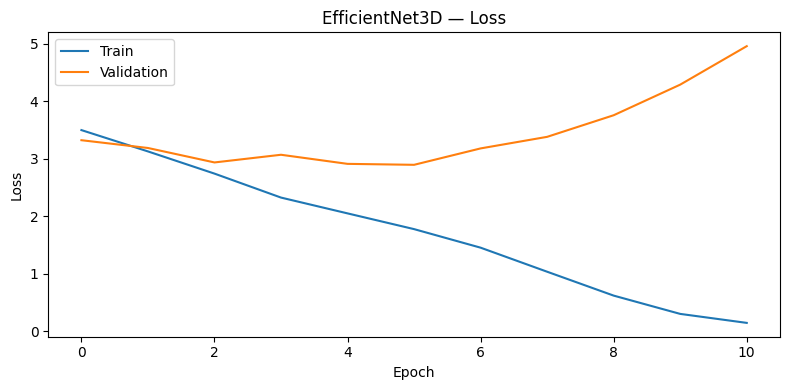


MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.8088    0.7358    0.7706       299
     Modic 2     0.5885    0.6848    0.6331       165

    accuracy                         0.7177       464
   macro avg     0.6987    0.7103    0.7018       464
weighted avg     0.7305    0.7177    0.7217       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.5094    0.3600    0.4219        75
          P2     0.4190    0.4944    0.4536        89
          P3     0.4368    0.5507    0.4872       138
          P4     0.4950    0.5051    0.5000        99
          P5     0.6452    0.3175    0.4255        63

    accuracy                         0.4677       464
   macro avg     0.5011    0.4455    0.4576       464
weighted avg     0.4858    0.4677    0.4645       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.8019    0.7444    0.7721       223
         

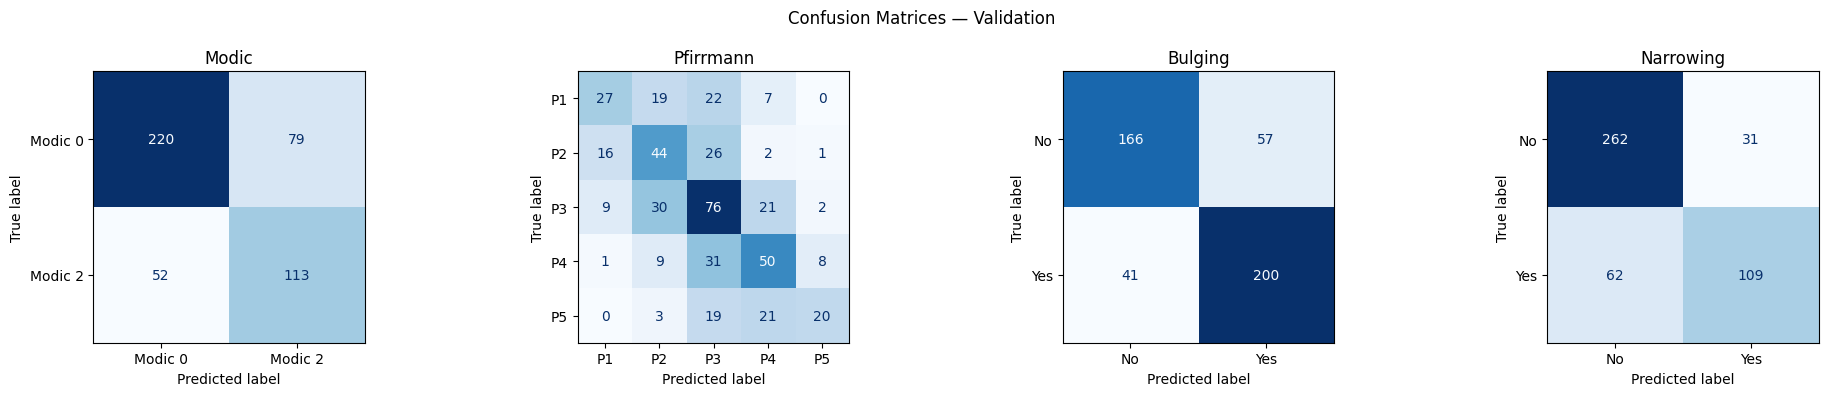

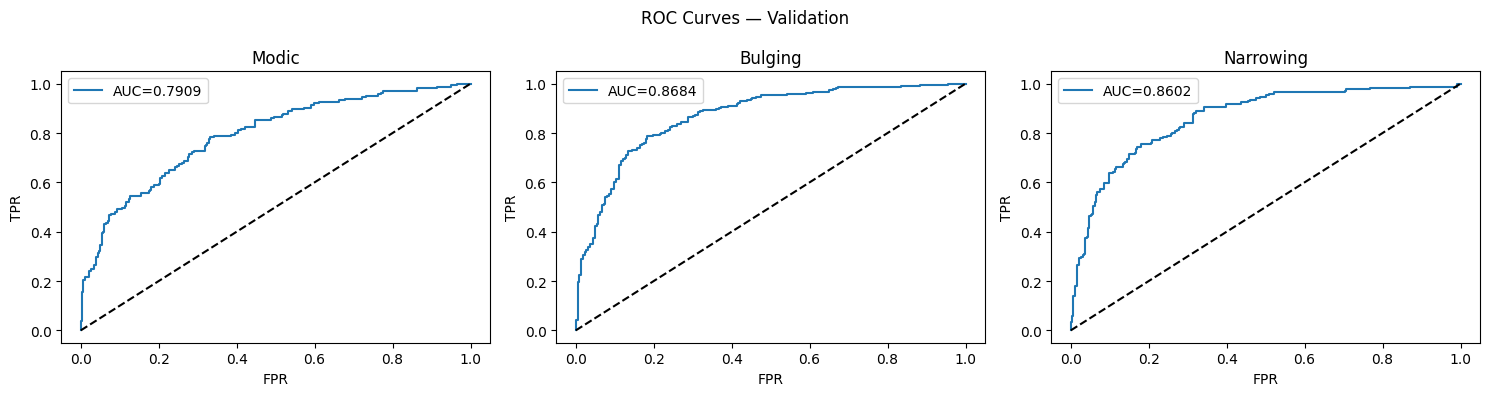


MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.7888    0.7993    0.7940       299
     Modic 2     0.6296    0.6145    0.6220       166

    accuracy                         0.7333       465
   macro avg     0.7092    0.7069    0.7080       465
weighted avg     0.7320    0.7333    0.7326       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.5455    0.4286    0.4800        70
          P2     0.4017    0.4087    0.4052       115
          P3     0.3838    0.5221    0.4424       136
          P4     0.3875    0.3444    0.3647        90
          P5     0.5714    0.2963    0.3902        54

    accuracy                         0.4194       465
   macro avg     0.4580    0.4000    0.4165       465
weighted avg     0.4351    0.4194    0.4177       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.8182    0.7941    0.8060       238
         Yes     0.7906    

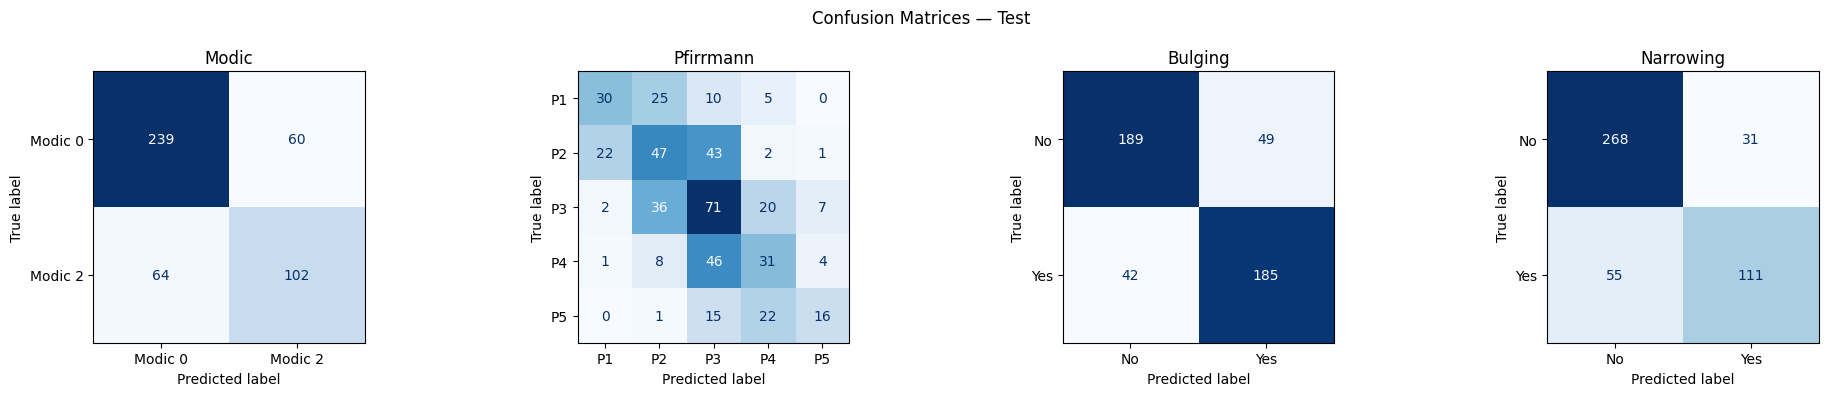

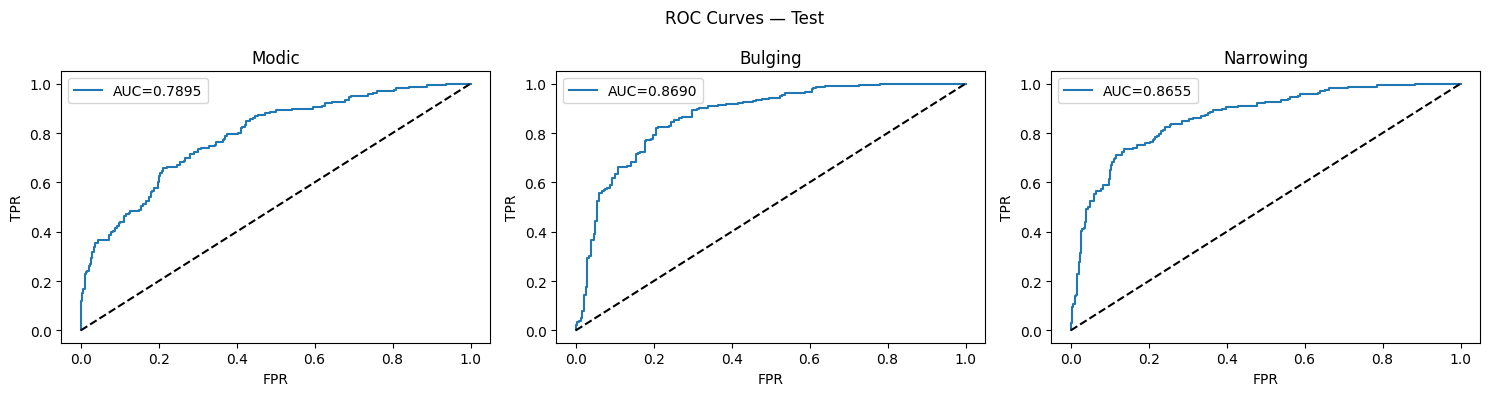

In [11]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("GPU:", torch.cuda.get_device_name(0))

DATA_DIR     = "/kaggle/input/datasets/prasanth6/lumbar-spine-disc/disc_samples_final_v2"
TARGET_SHAPE = (32, 128, 128)
BATCH_SIZE   = 4
EPOCHS       = 25
LR           = 1e-4
PATIENCE     = 5

# =========================================================
# DATASET — resize + z-score
# =========================================================
class DiscDataset(Dataset):
    def __init__(self, files, target_shape=TARGET_SHAPE):
        self.target_shape = target_shape
        self.files = []
        skipped = 0
        for f in files:
            try:
                data  = np.load(f, allow_pickle=True)
                modic = int(data["labels"].item()["modic"])
                if modic in [0, 2]:
                    self.files.append(f)
                else:
                    skipped += 1
            except Exception as e:
                print(f"  [WARN] {f}: {e}")
                skipped += 1
        print(f"  Loaded {len(self.files)} samples | skipped {skipped}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data  = np.load(self.files[idx], allow_pickle=True)
        image = torch.tensor(data["image"],
                             dtype=torch.float32).unsqueeze(0)
        # Resize to fixed shape
        image = F.interpolate(
            image.unsqueeze(0), size=self.target_shape,
            mode="trilinear", align_corners=False
        ).squeeze(0)
        # Z-score normalise per volume
        image = (image - image.mean()) / (image.std() + 1e-6)

        labels    = data["labels"].item()
        modic_raw = int(labels["modic"])
        pfirrmann = max(0, min(int(labels["pfirrmann"]) - 1, 4))

        return image, {
            "modic":     torch.tensor(
                0 if modic_raw == 0 else 1, dtype=torch.long),
            "pfirrmann": torch.tensor(pfirrmann, dtype=torch.long),
            "bulging":   torch.tensor(
                float(labels["bulging"]), dtype=torch.float32),
            "narrowing": torch.tensor(
                float(labels["narrowing"]), dtype=torch.float32),
        }


# =========================================================
# STRATIFIED SPLIT — filter before splitting
# =========================================================
all_files = sorted([
    os.path.join(DATA_DIR, f)
    for f in os.listdir(DATA_DIR) if f.endswith(".npz")
])
print(f"Total .npz files: {len(all_files)}")

labels_for_split, valid_files = [], []
for f in all_files:
    try:
        d = np.load(f, allow_pickle=True)
        m = int(d["labels"].item()["modic"])
        if m in [0, 2]:
            labels_for_split.append(m)
            valid_files.append(f)
    except Exception:
        pass

print(f"Valid files (modic 0 or 2): {len(valid_files)}")

train_files, temp_files, _, temp_labels = train_test_split(
    valid_files, labels_for_split,
    test_size=0.30, stratify=labels_for_split, random_state=42
)
val_files, test_files = train_test_split(
    temp_files, test_size=0.50,
    stratify=temp_labels, random_state=42
)
print(f"\nSplit → Train:{len(train_files)} Val:{len(val_files)} Test:{len(test_files)}")

print("\nBuilding Train dataset:")
train_ds = DiscDataset(train_files)
print("Building Val dataset:")
val_ds   = DiscDataset(val_files)
print("Building Test dataset:")
test_ds  = DiscDataset(test_files)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)


# =========================================================
# EFFICIENTNET 3D
# Core building block: MBConv3D (Mobile Inverted Bottleneck)
# with Squeeze-and-Excitation (SE) attention
# =========================================================

def _make_divisible(v, divisor=8):
    """Ensure channel count is divisible by divisor."""
    return max(divisor, int(v + divisor / 2) // divisor * divisor)


class Swish(nn.Module):
    """Swish activation: x * sigmoid(x)."""
    def forward(self, x):
        return x * torch.sigmoid(x)


class SqueezeExcitation3D(nn.Module):
    """Channel-wise SE attention block for 3D feature maps."""
    def __init__(self, in_ch, se_ratio=0.25):
        super().__init__()
        se_ch = max(1, int(in_ch * se_ratio))
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool3d(1),
            nn.Flatten(),
            nn.Linear(in_ch, se_ch),
            Swish(),
            nn.Linear(se_ch, in_ch),
            nn.Sigmoid()
        )

    def forward(self, x):
        scale = self.se(x).view(x.size(0), x.size(1), 1, 1, 1)
        return x * scale


class MBConv3D(nn.Module):
    """
    3D Mobile Inverted Bottleneck Conv (MBConv) with:
      - Expansion pointwise conv
      - 3D depthwise conv
      - Squeeze-and-Excitation
      - Projection pointwise conv
      - Residual skip if in_ch == out_ch and stride == 1
    """
    def __init__(self, in_ch, out_ch, stride=1,
                 expand_ratio=6, se_ratio=0.25):
        super().__init__()
        mid_ch = _make_divisible(in_ch * expand_ratio)
        self.use_skip = (stride == 1 and in_ch == out_ch)

        layers = []
        # Expansion
        if expand_ratio != 1:
            layers += [
                nn.Conv3d(in_ch, mid_ch, 1, bias=False),
                nn.GroupNorm(8, mid_ch),
                Swish()
            ]
        # Depthwise conv
        layers += [
            nn.Conv3d(mid_ch, mid_ch, 3, stride=stride,
                      padding=1, groups=mid_ch, bias=False),
            nn.GroupNorm(8, mid_ch),
            Swish()
        ]
        # SE attention
        layers.append(SqueezeExcitation3D(mid_ch, se_ratio))
        # Projection
        layers += [
            nn.Conv3d(mid_ch, out_ch, 1, bias=False),
            nn.GroupNorm(8, out_ch)
        ]
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        out = self.block(x)
        if self.use_skip:
            out = out + x
        return out


class EfficientNet3D(nn.Module):
    """
    3D EfficientNet-inspired architecture.

    Stage layout (channels, stride, repeat):
      Stem:    1  → 32,  stride 2
      Stage 1: 32 → 16,  stride 1, ×1  (no expand, SE only)
      Stage 2: 16 → 24,  stride 2, ×2
      Stage 3: 24 → 40,  stride 2, ×2
      Stage 4: 40 → 80,  stride 2, ×2
      Stage 5: 80 → 112, stride 1, ×2
      Stage 6: 112→ 192, stride 2, ×2
      Head:    192→ 320, 1×1 conv
      Pool + Dropout + Task heads
    """
    def __init__(self):
        super().__init__()

        # Stem
        self.stem = nn.Sequential(
            nn.Conv3d(1, 32, 3, stride=2, padding=1, bias=False),
            nn.GroupNorm(8, 32),
            Swish()
        )

        # MBConv stages
        self.stage1 = self._make_stage(32,  16,  stride=1,
                                       expand_ratio=1, n=1)
        self.stage2 = self._make_stage(16,  24,  stride=2,
                                       expand_ratio=6, n=2)
        self.stage3 = self._make_stage(24,  40,  stride=2,
                                       expand_ratio=6, n=2)
        self.stage4 = self._make_stage(40,  80,  stride=2,
                                       expand_ratio=6, n=2)
        self.stage5 = self._make_stage(80,  112, stride=1,
                                       expand_ratio=6, n=2)
        self.stage6 = self._make_stage(112, 192, stride=2,
                                       expand_ratio=6, n=2)

        # Head conv
        self.head_conv = nn.Sequential(
            nn.Conv3d(192, 320, 1, bias=False),
            nn.GroupNorm(8, 320),
            Swish()
        )

        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)

        # Task heads — modic binary (0 vs 2)
        self.head_modic = nn.Sequential(
            nn.Linear(320, 128), nn.ReLU(), nn.Linear(128, 2))
        self.head_pfirrmann = nn.Sequential(
            nn.Linear(320, 128), nn.ReLU(), nn.Linear(128, 5))
        self.head_bulging = nn.Sequential(
            nn.Linear(320, 64),  nn.ReLU(), nn.Linear(64, 1))
        self.head_narrowing = nn.Sequential(
            nn.Linear(320, 64),  nn.ReLU(), nn.Linear(64, 1))

    @staticmethod
    def _make_stage(in_ch, out_ch, stride, expand_ratio, n):
        layers = [MBConv3D(in_ch, out_ch, stride=stride,
                           expand_ratio=expand_ratio)]
        for _ in range(n - 1):
            layers.append(MBConv3D(out_ch, out_ch, stride=1,
                                   expand_ratio=expand_ratio))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.stage5(x)
        x = self.stage6(x)
        x = self.head_conv(x)
        x = self.dropout(self.pool(x).flatten(1))

        return {
            "modic":     self.head_modic(x),
            "pfirrmann": self.head_pfirrmann(x),
            "bulging":   self.head_bulging(x).squeeze(1),
            "narrowing": self.head_narrowing(x).squeeze(1),
        }


# =========================================================
# LOSS
# =========================================================
ce  = nn.CrossEntropyLoss()
bce = nn.BCEWithLogitsLoss()

def multitask_loss(out, tgt):
    return (
        ce( out["modic"],     tgt["modic"])     +
        ce( out["pfirrmann"], tgt["pfirrmann"]) +
        bce(out["bulging"],   tgt["bulging"])   +
        bce(out["narrowing"], tgt["narrowing"])
    )


# =========================================================
# TRAIN / EVAL
# =========================================================
model     = EfficientNet3D().to(device)
optimizer = torch.optim.AdamW(model.parameters(),
                               lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS)
scaler    = GradScaler(enabled=True)

n_params = sum(p.numel() for p in model.parameters()
               if p.requires_grad)
print(f"\nEfficientNet3D params: {n_params:,}")


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total = 0.0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for img, tgt in loader:
            img = img.to(device)
            tgt = {k: v.to(device) for k, v in tgt.items()}
            if train:
                optimizer.zero_grad()
            with autocast(device.type):
                out  = model(img)
                loss = multitask_loss(out, tgt)
            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total += loss.item()
    return total / max(len(loader), 1)


train_losses, val_losses = [], []
best_val = np.inf
counter  = 0

for epoch in range(EPOCHS):
    tr = run_epoch(train_loader, train=True)
    vl = run_epoch(val_loader,   train=False)
    scheduler.step()
    train_losses.append(tr)
    val_losses.append(vl)
    print(f"Epoch {epoch+1:02d}/{EPOCHS}  |  "
          f"Train {tr:.4f}  |  Val {vl:.4f}")
    if vl < best_val:
        best_val = vl; counter = 0
        torch.save(model.state_dict(), "best_efficientnet3d.pth")
        print("  ✔ Saved best model")
    else:
        counter += 1
        if counter >= PATIENCE:
            print("Early stopping."); break

plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train")
plt.plot(val_losses,   label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("EfficientNet3D — Loss")
plt.legend(); plt.tight_layout(); plt.show()


# =========================================================
# EVALUATION
# =========================================================
def evaluate(loader, split_name="Test"):
    model.load_state_dict(
        torch.load("best_efficientnet3d.pth", map_location=device))
    model.eval()

    preds = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}
    probs = {k: [] for k in ["modic", "bulging", "narrowing"]}
    gts   = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}

    with torch.no_grad():
        for img, tgt in loader:
            img = img.to(device)
            out = model(img)

            p_m = torch.softmax(out["modic"], 1)[:, 1]
            probs["modic"].extend(p_m.cpu().numpy())
            preds["modic"].extend(
                out["modic"].argmax(1).cpu().numpy())
            gts["modic"].extend(tgt["modic"].numpy())

            preds["pfirrmann"].extend(
                out["pfirrmann"].argmax(1).cpu().numpy())
            gts["pfirrmann"].extend(tgt["pfirrmann"].numpy())

            p_b = torch.sigmoid(out["bulging"])
            probs["bulging"].extend(p_b.cpu().numpy())
            preds["bulging"].extend(
                (p_b > 0.5).long().cpu().numpy())
            gts["bulging"].extend(
                tgt["bulging"].long().numpy())

            p_n = torch.sigmoid(out["narrowing"])
            probs["narrowing"].extend(p_n.cpu().numpy())
            preds["narrowing"].extend(
                (p_n > 0.5).long().cpu().numpy())
            gts["narrowing"].extend(
                tgt["narrowing"].long().numpy())

    task_labels = {
        "modic":     (["Modic 0", "Modic 2"],
                      f"\nMODIC — {split_name}"),
        "pfirrmann": ([f"P{i+1}" for i in range(5)],
                      f"\nPFIRRMANN — {split_name}"),
        "bulging":   (["No", "Yes"],
                      f"\nBULGING — {split_name}"),
        "narrowing": (["No", "Yes"],
                      f"\nNARROWING — {split_name}"),
    }
    for task, (names, title) in task_labels.items():
        print(title)
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i < len(names)]
        print(classification_report(
            gts[task], preds[task], labels=present,
            target_names=used, digits=4, zero_division=0))

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    fig.suptitle(f"Confusion Matrices — {split_name}")
    for ax, (task, (names, _)) in zip(axes, task_labels.items()):
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i < len(names)]
        ConfusionMatrixDisplay(
            confusion_matrix(gts[task], preds[task]),
            display_labels=used
        ).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(task.capitalize())
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"ROC Curves — {split_name}")
    for ax, task in zip(axes, ["modic", "bulging", "narrowing"]):
        gt_arr   = np.array(gts[task])
        prob_arr = np.array(probs[task])
        if len(np.unique(gt_arr)) < 2:
            ax.set_title(f"{task} (1 class)"); continue
        fpr, tpr, _ = roc_curve(gt_arr, prob_arr)
        ax.plot(fpr, tpr, label=f"AUC={auc(fpr, tpr):.4f}")
        ax.plot([0, 1], [0, 1], "k--")
        ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
        ax.set_title(task.capitalize()); ax.legend()
    plt.tight_layout(); plt.show()


evaluate(val_loader,  split_name="Validation")
evaluate(test_loader, split_name="Test")

**3D U-NET ENCODER**

Using device: cuda
GPU: Tesla P100-PCIE-16GB
Total .npz files: 3119
Valid files (modic 0 or 2): 3095

Split → Train:2166 Val:464 Test:465

Building Train dataset:
  Loaded 2166 samples | skipped 0
Building Val dataset:
  Loaded 464 samples | skipped 0
Building Test dataset:
  Loaded 465 samples | skipped 0

UNetEncoder3D params: 14,872,137
Epoch 01/25  |  Train 3.5938  |  Val 3.5854
  ✔ Saved best model
Epoch 02/25  |  Train 3.5772  |  Val 3.5846
  ✔ Saved best model
Epoch 03/25  |  Train 3.5231  |  Val 3.3973
  ✔ Saved best model
Epoch 04/25  |  Train 3.2085  |  Val 3.0829
  ✔ Saved best model
Epoch 05/25  |  Train 3.0649  |  Val 3.0807
  ✔ Saved best model
Epoch 06/25  |  Train 3.0290  |  Val 3.1540
Epoch 07/25  |  Train 2.9978  |  Val 3.1058
Epoch 08/25  |  Train 2.9613  |  Val 3.0213
  ✔ Saved best model
Epoch 09/25  |  Train 2.9210  |  Val 3.1071
Epoch 10/25  |  Train 2.8855  |  Val 2.9570
  ✔ Saved best model
Epoch 11/25  |  Train 2.8423  |  Val 3.0437
Epoch 12/25  |  Train 2.815

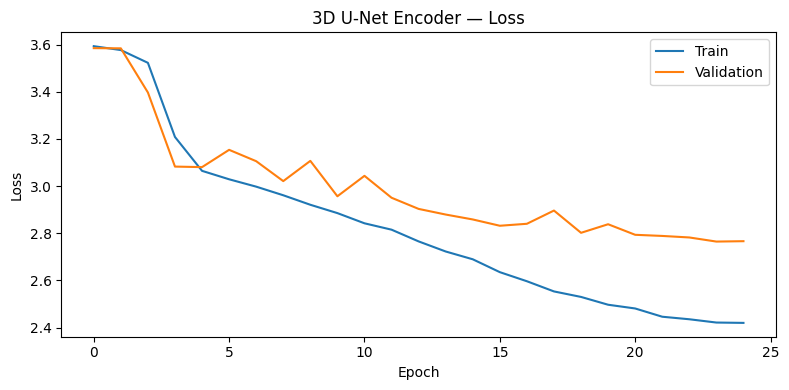


MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.7585    0.8194    0.7878       299
     Modic 2     0.6170    0.5273    0.5686       165

    accuracy                         0.7155       464
   macro avg     0.6878    0.6733    0.6782       464
weighted avg     0.7082    0.7155    0.7098       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.5484    0.2267    0.3208        75
          P2     0.4057    0.4831    0.4410        89
          P3     0.4494    0.5797    0.5063       138
          P4     0.4000    0.3232    0.3575        99
          P5     0.5072    0.5556    0.5303        63

    accuracy                         0.4461       464
   macro avg     0.4621    0.4337    0.4312       464
weighted avg     0.4543    0.4461    0.4353       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.8131    0.7220    0.7648       223
         

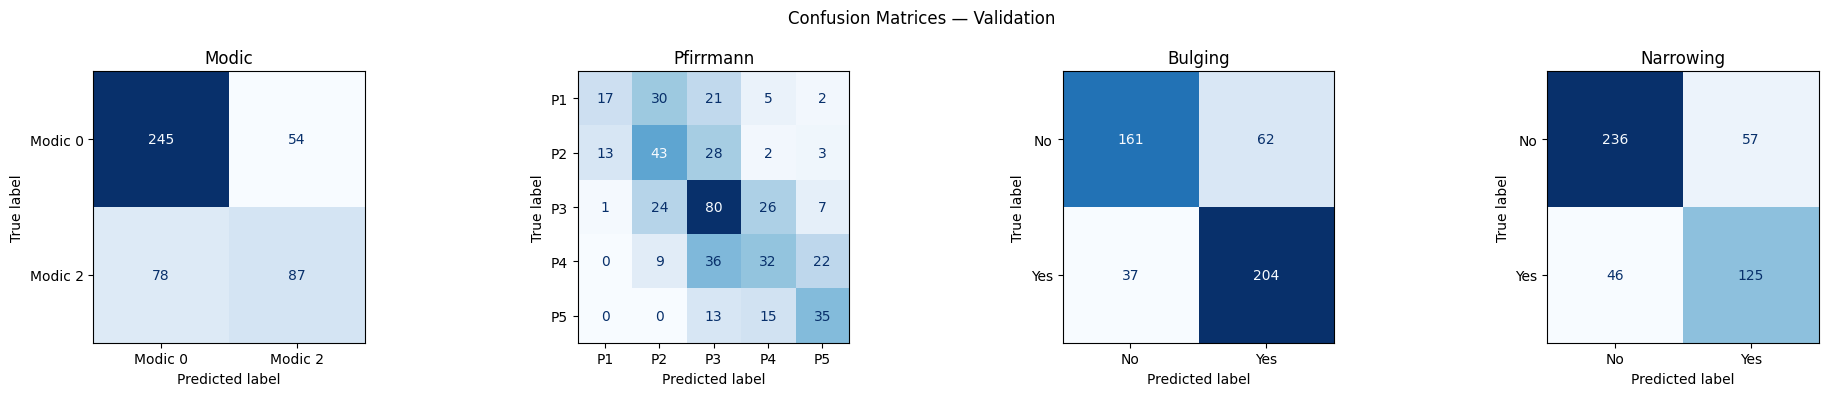

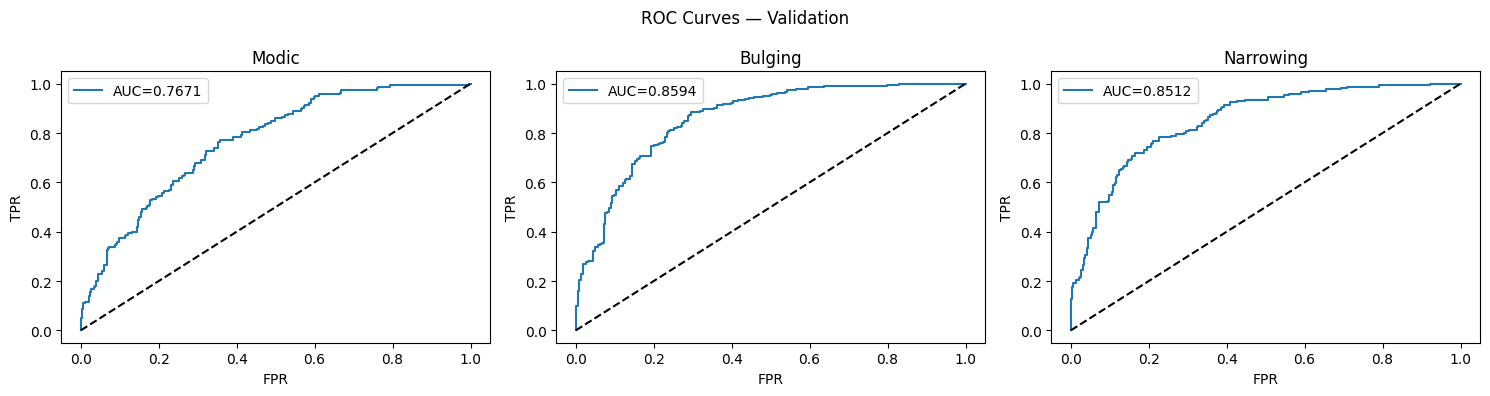


MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.7622    0.8361    0.7974       299
     Modic 2     0.6423    0.5301    0.5809       166

    accuracy                         0.7269       465
   macro avg     0.7023    0.6831    0.6892       465
weighted avg     0.7194    0.7269    0.7201       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.5625    0.2571    0.3529        70
          P2     0.4298    0.4522    0.4407       115
          P3     0.4036    0.4926    0.4437       136
          P4     0.4045    0.4000    0.4022        90
          P5     0.4035    0.4259    0.4144        54

    accuracy                         0.4215       465
   macro avg     0.4408    0.4056    0.4108       465
weighted avg     0.4342    0.4215    0.4179       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.8619    0.7605    0.8080       238
         Yes     0.7765    

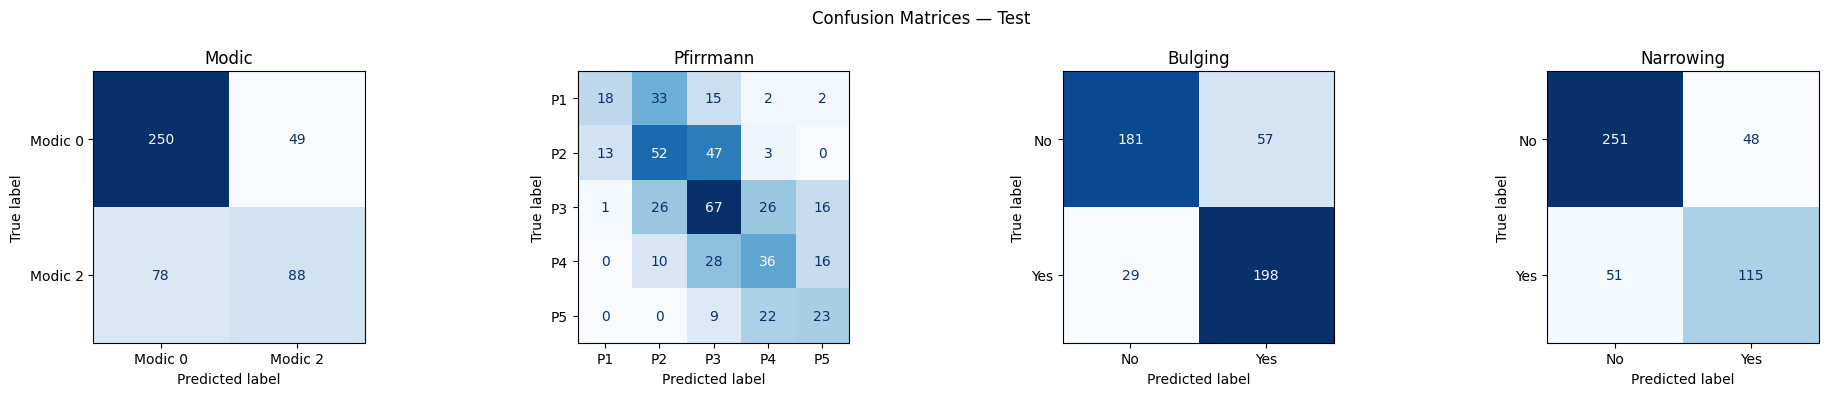

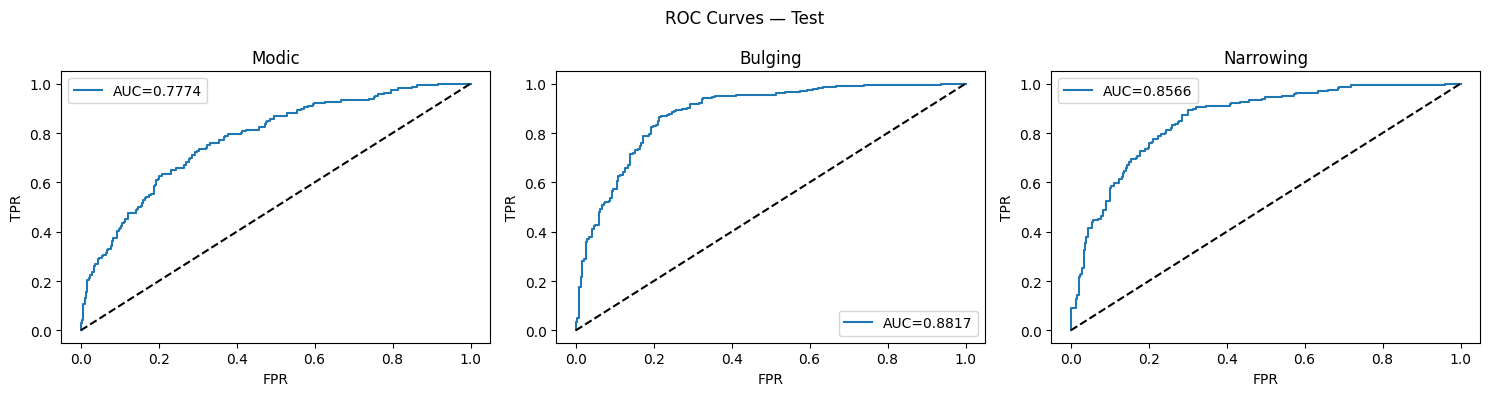

In [12]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("GPU:", torch.cuda.get_device_name(0))

DATA_DIR     = "/kaggle/input/datasets/prasanth6/lumbar-spine-disc/disc_samples_final_v2"
TARGET_SHAPE = (32, 128, 128)
BATCH_SIZE   = 4
EPOCHS       = 25
LR           = 1e-4
PATIENCE     = 5

# =========================================================
# DATASET — resize + z-score
# =========================================================
class DiscDataset(Dataset):
    def __init__(self, files, target_shape=TARGET_SHAPE):
        self.target_shape = target_shape
        self.files = []
        skipped = 0
        for f in files:
            try:
                data  = np.load(f, allow_pickle=True)
                modic = int(data["labels"].item()["modic"])
                if modic in [0, 2]:
                    self.files.append(f)
                else:
                    skipped += 1
            except Exception as e:
                print(f"  [WARN] {f}: {e}")
                skipped += 1
        print(f"  Loaded {len(self.files)} samples | skipped {skipped}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data  = np.load(self.files[idx], allow_pickle=True)
        image = torch.tensor(data["image"],
                             dtype=torch.float32).unsqueeze(0)
        # Resize to fixed shape
        image = F.interpolate(
            image.unsqueeze(0), size=self.target_shape,
            mode="trilinear", align_corners=False
        ).squeeze(0)
        # Z-score normalise per volume
        image = (image - image.mean()) / (image.std() + 1e-6)

        labels    = data["labels"].item()
        modic_raw = int(labels["modic"])
        pfirrmann = max(0, min(int(labels["pfirrmann"]) - 1, 4))

        return image, {
            "modic":     torch.tensor(
                0 if modic_raw == 0 else 1, dtype=torch.long),
            "pfirrmann": torch.tensor(pfirrmann, dtype=torch.long),
            "bulging":   torch.tensor(
                float(labels["bulging"]), dtype=torch.float32),
            "narrowing": torch.tensor(
                float(labels["narrowing"]), dtype=torch.float32),
        }


# =========================================================
# STRATIFIED SPLIT — filter before splitting
# =========================================================
all_files = sorted([
    os.path.join(DATA_DIR, f)
    for f in os.listdir(DATA_DIR) if f.endswith(".npz")
])
print(f"Total .npz files: {len(all_files)}")

labels_for_split, valid_files = [], []
for f in all_files:
    try:
        d = np.load(f, allow_pickle=True)
        m = int(d["labels"].item()["modic"])
        if m in [0, 2]:
            labels_for_split.append(m)
            valid_files.append(f)
    except Exception:
        pass

print(f"Valid files (modic 0 or 2): {len(valid_files)}")

train_files, temp_files, _, temp_labels = train_test_split(
    valid_files, labels_for_split,
    test_size=0.30, stratify=labels_for_split, random_state=42
)
val_files, test_files = train_test_split(
    temp_files, test_size=0.50,
    stratify=temp_labels, random_state=42
)
print(f"\nSplit → Train:{len(train_files)} Val:{len(val_files)} Test:{len(test_files)}")

print("\nBuilding Train dataset:")
train_ds = DiscDataset(train_files)
print("Building Val dataset:")
val_ds   = DiscDataset(val_files)
print("Building Test dataset:")
test_ds  = DiscDataset(test_files)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)


# =========================================================
# 3D U-NET ENCODER
#
# Uses only the contracting (encoder) path of U-Net for
# classification. Each encoder block applies two Conv3D
# layers with GroupNorm + ReLU, followed by MaxPool3D.
# Skip-connection feature maps from each level are
# aggregated via AdaptiveAvgPool3d and concatenated to
# form a rich multi-scale feature vector for the heads.
# =========================================================

class ConvBlock3D(nn.Module):
    """Two consecutive Conv3D → GroupNorm → ReLU layers."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.GroupNorm(8, out_ch),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.GroupNorm(8, out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNetEncoder3D(nn.Module):
    """
    3D U-Net Encoder (contracting path only) for classification.

    Encoder levels:
      Level 1:  1  →  64  (no downsampling before)
      Level 2:  64 → 128  (MaxPool3D before)
      Level 3: 128 → 256  (MaxPool3D before)
      Level 4: 256 → 512  (MaxPool3D before)  ← bottleneck

    Multi-scale aggregation:
      Each level's feature map is squeezed with
      AdaptiveAvgPool3d(1) and concatenated →
      total feature dim = 64 + 128 + 256 + 512 = 960
    """
    def __init__(self):
        super().__init__()

        # Encoder blocks
        self.enc1 = ConvBlock3D(1,   64)
        self.enc2 = ConvBlock3D(64,  128)
        self.enc3 = ConvBlock3D(128, 256)
        self.enc4 = ConvBlock3D(256, 512)   # bottleneck

        self.pool = nn.MaxPool3d(2)
        self.gap  = nn.AdaptiveAvgPool3d(1)

        self.dropout = nn.Dropout(0.3)

        # Multi-scale feature dim: 64+128+256+512 = 960
        feat = 64 + 128 + 256 + 512

        # Task heads
        self.head_modic = nn.Sequential(
            nn.Linear(feat, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 2))
        self.head_pfirrmann = nn.Sequential(
            nn.Linear(feat, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 5))
        self.head_bulging = nn.Sequential(
            nn.Linear(feat, 128), nn.ReLU(),
            nn.Linear(128, 64),  nn.ReLU(),
            nn.Linear(64, 1))
        self.head_narrowing = nn.Sequential(
            nn.Linear(feat, 128), nn.ReLU(),
            nn.Linear(128, 64),  nn.ReLU(),
            nn.Linear(64, 1))

    def forward(self, x):
        # Encoder — save feature maps at each level
        s1 = self.enc1(x)                   # (B, 64,  D,   H,   W)
        s2 = self.enc2(self.pool(s1))        # (B, 128, D/2, H/2, W/2)
        s3 = self.enc3(self.pool(s2))        # (B, 256, D/4, H/4, W/4)
        s4 = self.enc4(self.pool(s3))        # (B, 512, D/8, H/8, W/8)

        # Multi-scale global average pooling → flatten each level
        f1 = self.gap(s1).flatten(1)         # (B, 64)
        f2 = self.gap(s2).flatten(1)         # (B, 128)
        f3 = self.gap(s3).flatten(1)         # (B, 256)
        f4 = self.gap(s4).flatten(1)         # (B, 512)

        # Concatenate all scales → (B, 960)
        feat = self.dropout(torch.cat([f1, f2, f3, f4], dim=1))

        return {
            "modic":     self.head_modic(feat),
            "pfirrmann": self.head_pfirrmann(feat),
            "bulging":   self.head_bulging(feat).squeeze(1),
            "narrowing": self.head_narrowing(feat).squeeze(1),
        }


# =========================================================
# LOSS
# =========================================================
ce  = nn.CrossEntropyLoss()
bce = nn.BCEWithLogitsLoss()

def multitask_loss(out, tgt):
    return (
        ce( out["modic"],     tgt["modic"])     +
        ce( out["pfirrmann"], tgt["pfirrmann"]) +
        bce(out["bulging"],   tgt["bulging"])   +
        bce(out["narrowing"], tgt["narrowing"])
    )


# =========================================================
# TRAIN / EVAL
# =========================================================
model     = UNetEncoder3D().to(device)
optimizer = torch.optim.AdamW(model.parameters(),
                               lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS)
scaler    = GradScaler(enabled=True)

n_params = sum(p.numel() for p in model.parameters()
               if p.requires_grad)
print(f"\nUNetEncoder3D params: {n_params:,}")


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total = 0.0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for img, tgt in loader:
            img = img.to(device)
            tgt = {k: v.to(device) for k, v in tgt.items()}
            if train:
                optimizer.zero_grad()
            with autocast(device.type):
                out  = model(img)
                loss = multitask_loss(out, tgt)
            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total += loss.item()
    return total / max(len(loader), 1)


train_losses, val_losses = [], []
best_val = np.inf
counter  = 0

for epoch in range(EPOCHS):
    tr = run_epoch(train_loader, train=True)
    vl = run_epoch(val_loader,   train=False)
    scheduler.step()
    train_losses.append(tr)
    val_losses.append(vl)
    print(f"Epoch {epoch+1:02d}/{EPOCHS}  |  "
          f"Train {tr:.4f}  |  Val {vl:.4f}")
    if vl < best_val:
        best_val = vl; counter = 0
        torch.save(model.state_dict(), "best_unet_encoder3d.pth")
        print("  ✔ Saved best model")
    else:
        counter += 1
        if counter >= PATIENCE:
            print("Early stopping."); break

plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train")
plt.plot(val_losses,   label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("3D U-Net Encoder — Loss")
plt.legend(); plt.tight_layout(); plt.show()


# =========================================================
# EVALUATION
# =========================================================
def evaluate(loader, split_name="Test"):
    model.load_state_dict(
        torch.load("best_unet_encoder3d.pth", map_location=device))
    model.eval()

    preds = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}
    probs = {k: [] for k in ["modic", "bulging", "narrowing"]}
    gts   = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}

    with torch.no_grad():
        for img, tgt in loader:
            img = img.to(device)
            out = model(img)

            p_m = torch.softmax(out["modic"], 1)[:, 1]
            probs["modic"].extend(p_m.cpu().numpy())
            preds["modic"].extend(
                out["modic"].argmax(1).cpu().numpy())
            gts["modic"].extend(tgt["modic"].numpy())

            preds["pfirrmann"].extend(
                out["pfirrmann"].argmax(1).cpu().numpy())
            gts["pfirrmann"].extend(tgt["pfirrmann"].numpy())

            p_b = torch.sigmoid(out["bulging"])
            probs["bulging"].extend(p_b.cpu().numpy())
            preds["bulging"].extend(
                (p_b > 0.5).long().cpu().numpy())
            gts["bulging"].extend(
                tgt["bulging"].long().numpy())

            p_n = torch.sigmoid(out["narrowing"])
            probs["narrowing"].extend(p_n.cpu().numpy())
            preds["narrowing"].extend(
                (p_n > 0.5).long().cpu().numpy())
            gts["narrowing"].extend(
                tgt["narrowing"].long().numpy())

    task_labels = {
        "modic":     (["Modic 0", "Modic 2"],
                      f"\nMODIC — {split_name}"),
        "pfirrmann": ([f"P{i+1}" for i in range(5)],
                      f"\nPFIRRMANN — {split_name}"),
        "bulging":   (["No", "Yes"],
                      f"\nBULGING — {split_name}"),
        "narrowing": (["No", "Yes"],
                      f"\nNARROWING — {split_name}"),
    }
    for task, (names, title) in task_labels.items():
        print(title)
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i < len(names)]
        print(classification_report(
            gts[task], preds[task], labels=present,
            target_names=used, digits=4, zero_division=0))

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    fig.suptitle(f"Confusion Matrices — {split_name}")
    for ax, (task, (names, _)) in zip(axes, task_labels.items()):
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i < len(names)]
        ConfusionMatrixDisplay(
            confusion_matrix(gts[task], preds[task]),
            display_labels=used
        ).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(task.capitalize())
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"ROC Curves — {split_name}")
    for ax, task in zip(axes, ["modic", "bulging", "narrowing"]):
        gt_arr   = np.array(gts[task])
        prob_arr = np.array(probs[task])
        if len(np.unique(gt_arr)) < 2:
            ax.set_title(f"{task} (1 class)"); continue
        fpr, tpr, _ = roc_curve(gt_arr, prob_arr)
        ax.plot(fpr, tpr, label=f"AUC={auc(fpr, tpr):.4f}")
        ax.plot([0, 1], [0, 1], "k--")
        ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
        ax.set_title(task.capitalize()); ax.legend()
    plt.tight_layout(); plt.show()


evaluate(val_loader,  split_name="Validation")
evaluate(test_loader, split_name="Test")

**MOBILENET 3D**

Using device: cuda
GPU: Tesla P100-PCIE-16GB
Total .npz files: 3119
Valid files (modic 0 or 2): 3095

Split → Train:2166 Val:464 Test:465

Building Train dataset:
  Loaded 2166 samples | skipped 0
Building Val dataset:
  Loaded 464 samples | skipped 0
Building Test dataset:
  Loaded 465 samples | skipped 0

MobileNet3D params: 2,812,873
Epoch 01/25  |  Train 3.4994  |  Val 3.3509
  ✔ Saved best model
Epoch 02/25  |  Train 3.1315  |  Val 3.0380
  ✔ Saved best model
Epoch 03/25  |  Train 2.7443  |  Val 3.1189
Epoch 04/25  |  Train 2.3085  |  Val 3.0828
Epoch 05/25  |  Train 2.0052  |  Val 2.9503
  ✔ Saved best model
Epoch 06/25  |  Train 1.7772  |  Val 3.1670
Epoch 07/25  |  Train 1.5002  |  Val 3.2305
Epoch 08/25  |  Train 1.1148  |  Val 3.7116
Epoch 09/25  |  Train 0.7389  |  Val 4.1422
Epoch 10/25  |  Train 0.4238  |  Val 5.6061
Early stopping.


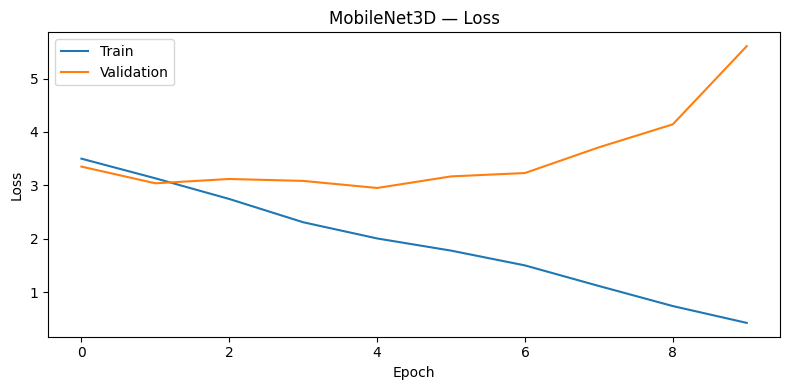


MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.7355    0.8462    0.7869       299
     Modic 2     0.6167    0.4485    0.5193       165

    accuracy                         0.7047       464
   macro avg     0.6761    0.6473    0.6531       464
weighted avg     0.6932    0.7047    0.6918       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.5455    0.0800    0.1395        75
          P2     0.3750    0.5393    0.4424        89
          P3     0.4294    0.5290    0.4740       138
          P4     0.3805    0.4343    0.4057        99
          P5     0.5952    0.3968    0.4762        63

    accuracy                         0.4203       464
   macro avg     0.4651    0.3959    0.3876       464
weighted avg     0.4498    0.4203    0.3996       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.7905    0.7444    0.7667       223
         

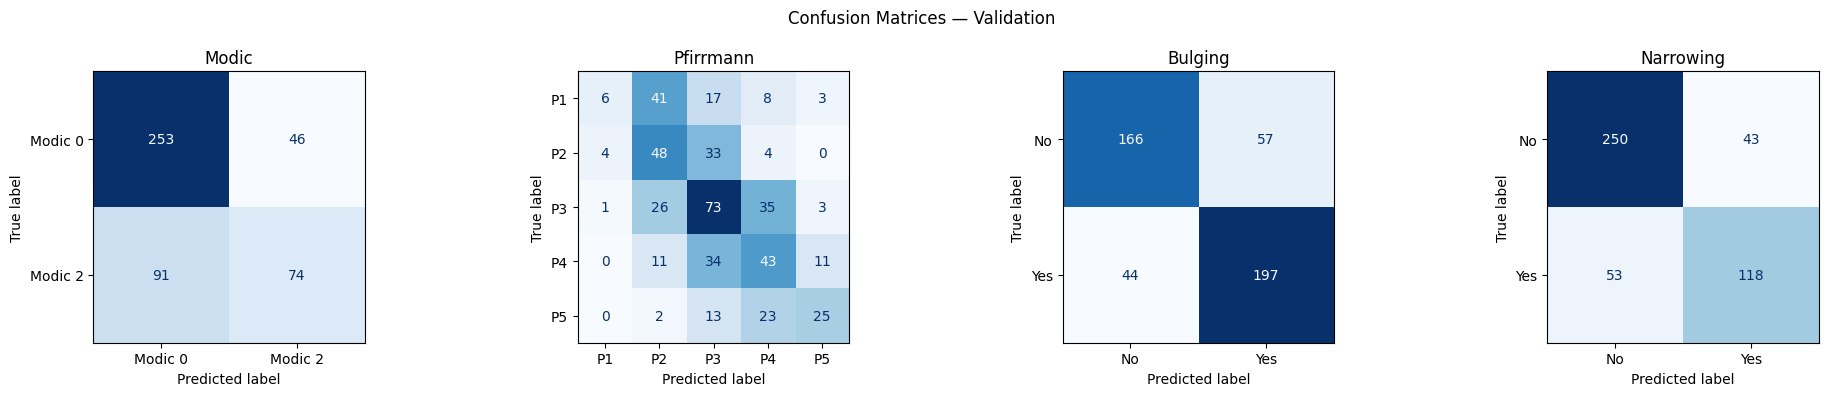

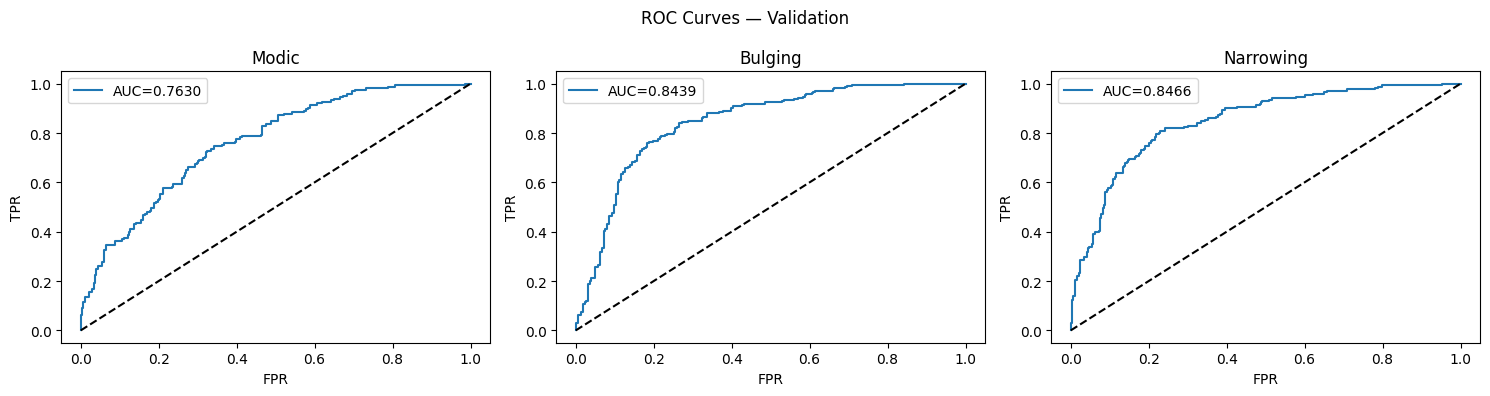


MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.7331    0.8729    0.7969       299
     Modic 2     0.6514    0.4277    0.5164       166

    accuracy                         0.7140       465
   macro avg     0.6923    0.6503    0.6567       465
weighted avg     0.7040    0.7140    0.6968       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.5769    0.2143    0.3125        70
          P2     0.4463    0.4696    0.4576       115
          P3     0.4068    0.5294    0.4601       136
          P4     0.3243    0.4000    0.3582        90
          P5     0.6000    0.3333    0.4286        54

    accuracy                         0.4194       465
   macro avg     0.4709    0.3893    0.4034       465
weighted avg     0.4486    0.4194    0.4139       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.8349    0.7647    0.7982       238
         Yes     0.7733    

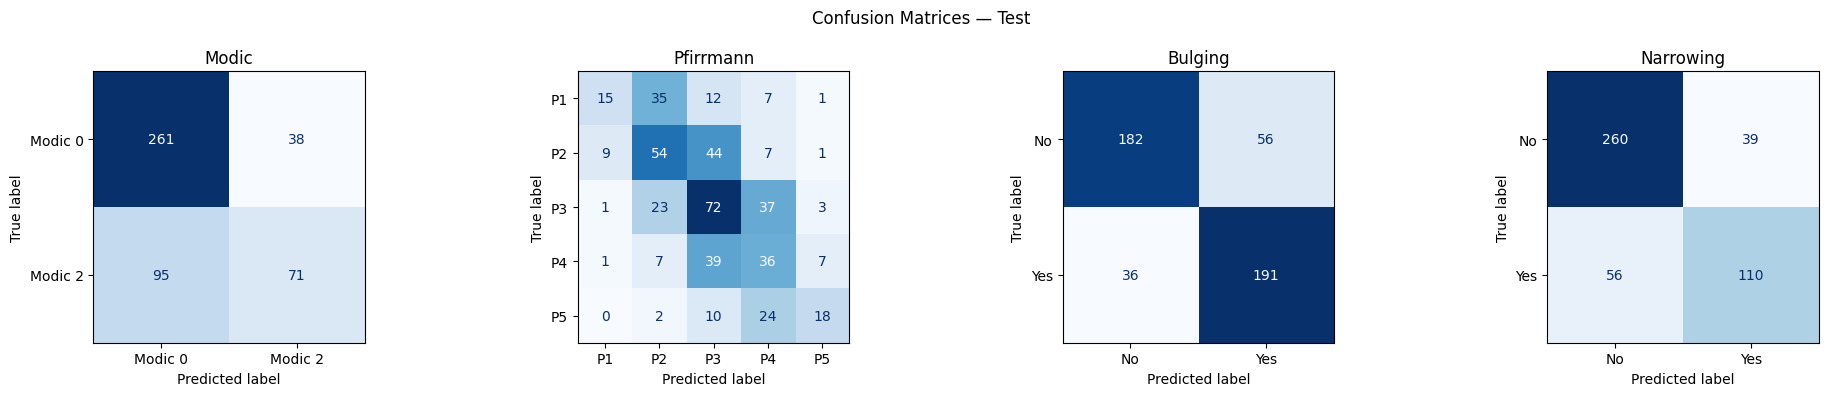

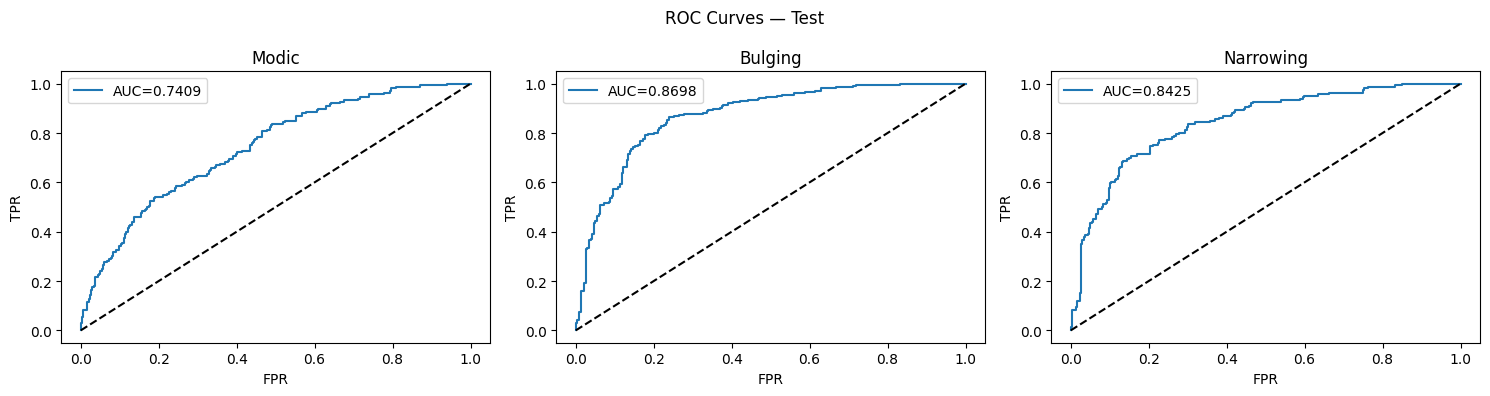

In [13]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("GPU:", torch.cuda.get_device_name(0))

DATA_DIR     = "/kaggle/input/datasets/prasanth6/lumbar-spine-disc/disc_samples_final_v2"
TARGET_SHAPE = (32, 128, 128)
BATCH_SIZE   = 4
EPOCHS       = 25
LR           = 1e-4
PATIENCE     = 5

# =========================================================
# DATASET — resize + z-score
# =========================================================
class DiscDataset(Dataset):
    def __init__(self, files, target_shape=TARGET_SHAPE):
        self.target_shape = target_shape
        self.files = []
        skipped = 0
        for f in files:
            try:
                data  = np.load(f, allow_pickle=True)
                modic = int(data["labels"].item()["modic"])
                if modic in [0, 2]:
                    self.files.append(f)
                else:
                    skipped += 1
            except Exception as e:
                print(f"  [WARN] {f}: {e}")
                skipped += 1
        print(f"  Loaded {len(self.files)} samples | skipped {skipped}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data  = np.load(self.files[idx], allow_pickle=True)
        image = torch.tensor(data["image"],
                             dtype=torch.float32).unsqueeze(0)
        # Resize to fixed shape
        image = F.interpolate(
            image.unsqueeze(0), size=self.target_shape,
            mode="trilinear", align_corners=False
        ).squeeze(0)
        # Z-score normalise per volume
        image = (image - image.mean()) / (image.std() + 1e-6)

        labels    = data["labels"].item()
        modic_raw = int(labels["modic"])
        pfirrmann = max(0, min(int(labels["pfirrmann"]) - 1, 4))

        return image, {
            "modic":     torch.tensor(
                0 if modic_raw == 0 else 1, dtype=torch.long),
            "pfirrmann": torch.tensor(pfirrmann, dtype=torch.long),
            "bulging":   torch.tensor(
                float(labels["bulging"]), dtype=torch.float32),
            "narrowing": torch.tensor(
                float(labels["narrowing"]), dtype=torch.float32),
        }


# =========================================================
# STRATIFIED SPLIT — filter before splitting
# =========================================================
all_files = sorted([
    os.path.join(DATA_DIR, f)
    for f in os.listdir(DATA_DIR) if f.endswith(".npz")
])
print(f"Total .npz files: {len(all_files)}")

labels_for_split, valid_files = [], []
for f in all_files:
    try:
        d = np.load(f, allow_pickle=True)
        m = int(d["labels"].item()["modic"])
        if m in [0, 2]:
            labels_for_split.append(m)
            valid_files.append(f)
    except Exception:
        pass

print(f"Valid files (modic 0 or 2): {len(valid_files)}")

train_files, temp_files, _, temp_labels = train_test_split(
    valid_files, labels_for_split,
    test_size=0.30, stratify=labels_for_split, random_state=42
)
val_files, test_files = train_test_split(
    temp_files, test_size=0.50,
    stratify=temp_labels, random_state=42
)
print(f"\nSplit → Train:{len(train_files)} Val:{len(val_files)} Test:{len(test_files)}")

print("\nBuilding Train dataset:")
train_ds = DiscDataset(train_files)
print("Building Val dataset:")
val_ds   = DiscDataset(val_files)
print("Building Test dataset:")
test_ds  = DiscDataset(test_files)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)


# =========================================================
# MOBILENET 3D
#
# Based on MobileNetV2: Inverted Residual blocks with
# 3D Depthwise Separable Convolutions.
#
# Each InvertedResidual3D block:
#   1) Pointwise expand  (1×1×1 conv, in_ch → in_ch * t)
#   2) Depthwise conv    (3×3×3, groups=expanded_ch)
#   3) Pointwise project (1×1×1 conv, expanded_ch → out_ch)
#   Residual skip added when in_ch == out_ch and stride == 1
#
# Stage layout (MobileNetV2-inspired):
#   Stem:    1   →  32, stride 2
#   Stage 1: 32  →  16, stride 1, t=1, ×1
#   Stage 2: 16  →  24, stride 2, t=6, ×2
#   Stage 3: 24  →  32, stride 2, t=6, ×2
#   Stage 4: 32  →  64, stride 2, t=6, ×2
#   Stage 5: 64  →  96, stride 1, t=6, ×2
#   Stage 6: 96  → 160, stride 2, t=6, ×2
#   Stage 7: 160 → 320, stride 1, t=6, ×1
#   Head conv: 320 → 1280 (1×1×1)
# =========================================================

class HardSwish(nn.Module):
    """Hard-Swish activation — lightweight alternative to Swish."""
    def forward(self, x):
        return x * F.relu6(x + 3.0) / 6.0


class DepthwiseSeparableConv3D(nn.Module):
    """
    3D Depthwise Separable Conv:
      depthwise (groups=in_ch) → GroupNorm → HardSwish
      pointwise (1×1×1)       → GroupNorm → HardSwish
    """
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.dw = nn.Sequential(
            nn.Conv3d(in_ch, in_ch, 3, stride=stride,
                      padding=1, groups=in_ch, bias=False),
            nn.GroupNorm(max(1, in_ch // 8), in_ch),
            HardSwish()
        )
        self.pw = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 1, bias=False),
            nn.GroupNorm(max(1, out_ch // 8), out_ch),
            HardSwish()
        )

    def forward(self, x):
        return self.pw(self.dw(x))


class InvertedResidual3D(nn.Module):
    """
    3D MobileNetV2 Inverted Residual block.
    Expand → Depthwise → Project with optional residual skip.
    """
    def __init__(self, in_ch, out_ch, stride=1, expand_ratio=6):
        super().__init__()
        mid_ch = in_ch * expand_ratio
        self.use_skip = (stride == 1 and in_ch == out_ch)

        layers = []
        # Expansion (skip if t=1)
        if expand_ratio != 1:
            layers += [
                nn.Conv3d(in_ch, mid_ch, 1, bias=False),
                nn.GroupNorm(max(1, mid_ch // 8), mid_ch),
                HardSwish()
            ]
        # Depthwise conv
        layers += [
            nn.Conv3d(mid_ch, mid_ch, 3, stride=stride,
                      padding=1, groups=mid_ch, bias=False),
            nn.GroupNorm(max(1, mid_ch // 8), mid_ch),
            HardSwish()
        ]
        # Projection (linear, no activation)
        layers += [
            nn.Conv3d(mid_ch, out_ch, 1, bias=False),
            nn.GroupNorm(max(1, out_ch // 8), out_ch)
        ]
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        out = self.block(x)
        if self.use_skip:
            out = out + x
        return out


class MobileNet3D(nn.Module):
    def __init__(self):
        super().__init__()

        # Stem
        self.stem = nn.Sequential(
            nn.Conv3d(1, 32, 3, stride=2, padding=1, bias=False),
            nn.GroupNorm(4, 32),
            HardSwish()
        )

        # Inverted residual stages (t=expand_ratio, c=out_ch,
        #                           n=repeats, s=first stride)
        self.stage1 = self._make_stage(32,  16,  stride=1,
                                       expand_ratio=1, n=1)
        self.stage2 = self._make_stage(16,  24,  stride=2,
                                       expand_ratio=6, n=2)
        self.stage3 = self._make_stage(24,  32,  stride=2,
                                       expand_ratio=6, n=2)
        self.stage4 = self._make_stage(32,  64,  stride=2,
                                       expand_ratio=6, n=2)
        self.stage5 = self._make_stage(64,  96,  stride=1,
                                       expand_ratio=6, n=2)
        self.stage6 = self._make_stage(96,  160, stride=2,
                                       expand_ratio=6, n=2)
        self.stage7 = self._make_stage(160, 320, stride=1,
                                       expand_ratio=6, n=1)

        # Head pointwise conv → 1280 channels
        self.head_conv = nn.Sequential(
            nn.Conv3d(320, 1280, 1, bias=False),
            nn.GroupNorm(max(1, 1280 // 8), 1280),
            HardSwish()
        )

        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)

        # Task heads — modic binary (Modic 0 vs Modic 2)
        self.head_modic = nn.Sequential(
            nn.Linear(1280, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 2))
        self.head_pfirrmann = nn.Sequential(
            nn.Linear(1280, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 5))
        self.head_bulging = nn.Sequential(
            nn.Linear(1280, 128), nn.ReLU(),
            nn.Linear(128, 64),  nn.ReLU(),
            nn.Linear(64, 1))
        self.head_narrowing = nn.Sequential(
            nn.Linear(1280, 128), nn.ReLU(),
            nn.Linear(128, 64),  nn.ReLU(),
            nn.Linear(64, 1))

    @staticmethod
    def _make_stage(in_ch, out_ch, stride, expand_ratio, n):
        layers = [InvertedResidual3D(in_ch, out_ch,
                                     stride=stride,
                                     expand_ratio=expand_ratio)]
        for _ in range(n - 1):
            layers.append(InvertedResidual3D(out_ch, out_ch,
                                             stride=1,
                                             expand_ratio=expand_ratio))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.stage5(x)
        x = self.stage6(x)
        x = self.stage7(x)
        x = self.head_conv(x)
        x = self.dropout(self.pool(x).flatten(1))

        return {
            "modic":     self.head_modic(x),
            "pfirrmann": self.head_pfirrmann(x),
            "bulging":   self.head_bulging(x).squeeze(1),
            "narrowing": self.head_narrowing(x).squeeze(1),
        }


# =========================================================
# LOSS
# =========================================================
ce  = nn.CrossEntropyLoss()
bce = nn.BCEWithLogitsLoss()

def multitask_loss(out, tgt):
    return (
        ce( out["modic"],     tgt["modic"])     +
        ce( out["pfirrmann"], tgt["pfirrmann"]) +
        bce(out["bulging"],   tgt["bulging"])   +
        bce(out["narrowing"], tgt["narrowing"])
    )


# =========================================================
# TRAIN / EVAL
# =========================================================
model     = MobileNet3D().to(device)
optimizer = torch.optim.AdamW(model.parameters(),
                               lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS)
scaler    = GradScaler(enabled=True)

n_params = sum(p.numel() for p in model.parameters()
               if p.requires_grad)
print(f"\nMobileNet3D params: {n_params:,}")


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total = 0.0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for img, tgt in loader:
            img = img.to(device)
            tgt = {k: v.to(device) for k, v in tgt.items()}
            if train:
                optimizer.zero_grad()
            with autocast(device.type):
                out  = model(img)
                loss = multitask_loss(out, tgt)
            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total += loss.item()
    return total / max(len(loader), 1)


train_losses, val_losses = [], []
best_val = np.inf
counter  = 0

for epoch in range(EPOCHS):
    tr = run_epoch(train_loader, train=True)
    vl = run_epoch(val_loader,   train=False)
    scheduler.step()
    train_losses.append(tr)
    val_losses.append(vl)
    print(f"Epoch {epoch+1:02d}/{EPOCHS}  |  "
          f"Train {tr:.4f}  |  Val {vl:.4f}")
    if vl < best_val:
        best_val = vl; counter = 0
        torch.save(model.state_dict(), "best_mobilenet3d.pth")
        print("  ✔ Saved best model")
    else:
        counter += 1
        if counter >= PATIENCE:
            print("Early stopping."); break

plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train")
plt.plot(val_losses,   label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("MobileNet3D — Loss")
plt.legend(); plt.tight_layout(); plt.show()


# =========================================================
# EVALUATION
# =========================================================
def evaluate(loader, split_name="Test"):
    model.load_state_dict(
        torch.load("best_mobilenet3d.pth", map_location=device))
    model.eval()

    preds = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}
    probs = {k: [] for k in ["modic", "bulging", "narrowing"]}
    gts   = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}

    with torch.no_grad():
        for img, tgt in loader:
            img = img.to(device)
            out = model(img)

            p_m = torch.softmax(out["modic"], 1)[:, 1]
            probs["modic"].extend(p_m.cpu().numpy())
            preds["modic"].extend(
                out["modic"].argmax(1).cpu().numpy())
            gts["modic"].extend(tgt["modic"].numpy())

            preds["pfirrmann"].extend(
                out["pfirrmann"].argmax(1).cpu().numpy())
            gts["pfirrmann"].extend(tgt["pfirrmann"].numpy())

            p_b = torch.sigmoid(out["bulging"])
            probs["bulging"].extend(p_b.cpu().numpy())
            preds["bulging"].extend(
                (p_b > 0.5).long().cpu().numpy())
            gts["bulging"].extend(
                tgt["bulging"].long().numpy())

            p_n = torch.sigmoid(out["narrowing"])
            probs["narrowing"].extend(p_n.cpu().numpy())
            preds["narrowing"].extend(
                (p_n > 0.5).long().cpu().numpy())
            gts["narrowing"].extend(
                tgt["narrowing"].long().numpy())

    task_labels = {
        "modic":     (["Modic 0", "Modic 2"],
                      f"\nMODIC — {split_name}"),
        "pfirrmann": ([f"P{i+1}" for i in range(5)],
                      f"\nPFIRRMANN — {split_name}"),
        "bulging":   (["No", "Yes"],
                      f"\nBULGING — {split_name}"),
        "narrowing": (["No", "Yes"],
                      f"\nNARROWING — {split_name}"),
    }
    for task, (names, title) in task_labels.items():
        print(title)
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i < len(names)]
        print(classification_report(
            gts[task], preds[task], labels=present,
            target_names=used, digits=4, zero_division=0))

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    fig.suptitle(f"Confusion Matrices — {split_name}")
    for ax, (task, (names, _)) in zip(axes, task_labels.items()):
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i < len(names)]
        ConfusionMatrixDisplay(
            confusion_matrix(gts[task], preds[task]),
            display_labels=used
        ).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(task.capitalize())
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"ROC Curves — {split_name}")
    for ax, task in zip(axes, ["modic", "bulging", "narrowing"]):
        gt_arr   = np.array(gts[task])
        prob_arr = np.array(probs[task])
        if len(np.unique(gt_arr)) < 2:
            ax.set_title(f"{task} (1 class)"); continue
        fpr, tpr, _ = roc_curve(gt_arr, prob_arr)
        ax.plot(fpr, tpr, label=f"AUC={auc(fpr, tpr):.4f}")
        ax.plot([0, 1], [0, 1], "k--")
        ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
        ax.set_title(task.capitalize()); ax.legend()
    plt.tight_layout(); plt.show()


evaluate(val_loader,  split_name="Validation")
evaluate(test_loader, split_name="Test")

**3D CNN**

Using device: cuda
GPU: Tesla P100-PCIE-16GB
Total .npz files: 3119
Valid files (modic 0 or 2): 3095

Split → Train:2166 Val:464 Test:465

Building Train dataset:
  Loaded 2166 samples | skipped 0
Building Val dataset:
  Loaded 464 samples | skipped 0
Building Test dataset:
  Loaded 465 samples | skipped 0

CNN3D params: 23,901,801
Epoch 01/25  |  Train 3.5793  |  Val 3.5322
  ✔ Saved best model
Epoch 02/25  |  Train 3.3508  |  Val 3.2101
  ✔ Saved best model
Epoch 03/25  |  Train 3.1830  |  Val 3.1352
  ✔ Saved best model
Epoch 04/25  |  Train 3.0610  |  Val 3.2575
Epoch 05/25  |  Train 2.9959  |  Val 3.0664
  ✔ Saved best model
Epoch 06/25  |  Train 2.9417  |  Val 2.9915
  ✔ Saved best model
Epoch 07/25  |  Train 2.8991  |  Val 2.9277
  ✔ Saved best model
Epoch 08/25  |  Train 2.8296  |  Val 2.9230
  ✔ Saved best model
Epoch 09/25  |  Train 2.7745  |  Val 2.8814
  ✔ Saved best model
Epoch 10/25  |  Train 2.7353  |  Val 2.8579
  ✔ Saved best model
Epoch 11/25  |  Train 2.6855  |  Val 

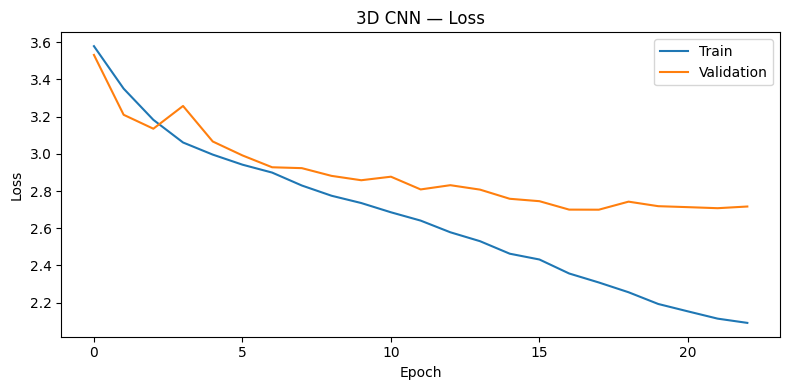


MODIC — Validation
              precision    recall  f1-score   support

     Modic 0     0.7890    0.8127    0.8007       299
     Modic 2     0.6410    0.6061    0.6231       165

    accuracy                         0.7392       464
   macro avg     0.7150    0.7094    0.7119       464
weighted avg     0.7364    0.7392    0.7375       464


PFIRRMANN — Validation
              precision    recall  f1-score   support

          P1     0.5000    0.1600    0.2424        75
          P2     0.4000    0.4719    0.4330        89
          P3     0.4497    0.4855    0.4669       138
          P4     0.4634    0.5758    0.5135        99
          P5     0.6032    0.6032    0.6032        63

    accuracy                         0.4655       464
   macro avg     0.4833    0.4593    0.4518       464
weighted avg     0.4721    0.4655    0.4526       464


BULGING — Validation
              precision    recall  f1-score   support

          No     0.7980    0.7085    0.7506       223
         

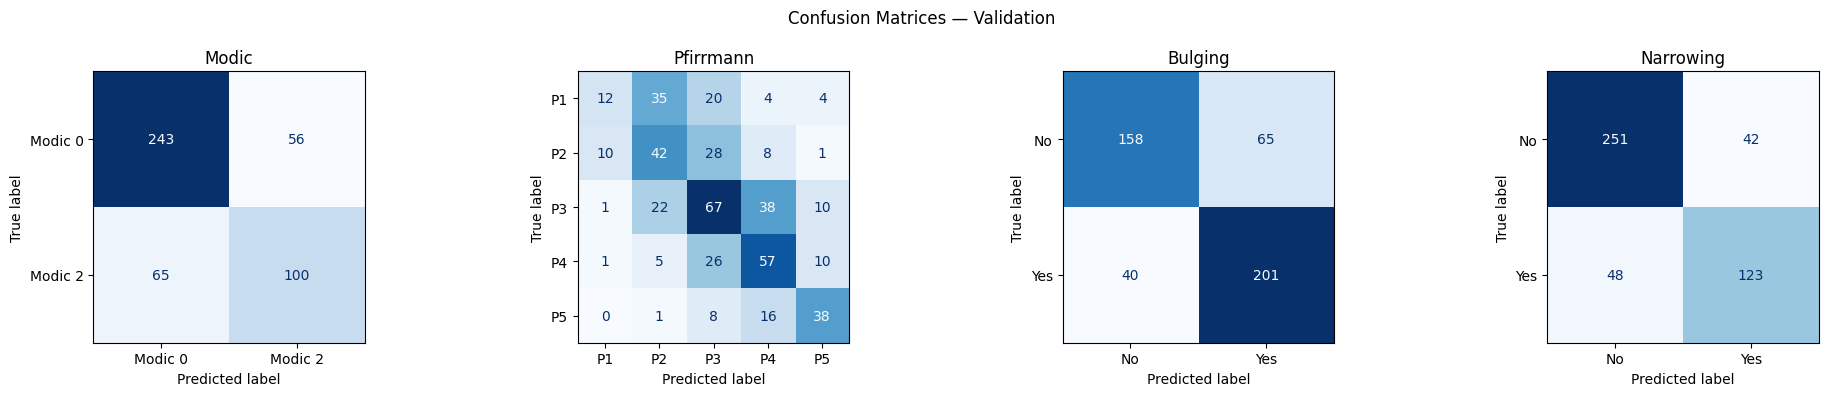

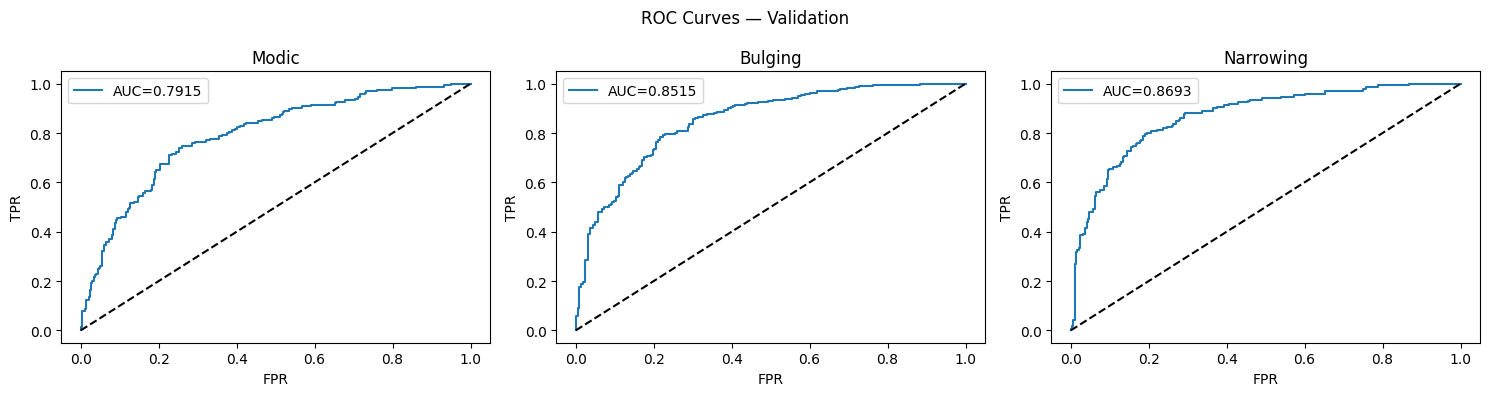


MODIC — Test
              precision    recall  f1-score   support

     Modic 0     0.7868    0.8395    0.8123       299
     Modic 2     0.6712    0.5904    0.6282       166

    accuracy                         0.7505       465
   macro avg     0.7290    0.7149    0.7203       465
weighted avg     0.7456    0.7505    0.7466       465


PFIRRMANN — Test
              precision    recall  f1-score   support

          P1     0.5882    0.2857    0.3846        70
          P2     0.4380    0.4609    0.4492       115
          P3     0.3889    0.4118    0.4000       136
          P4     0.3739    0.4778    0.4195        90
          P5     0.6667    0.6296    0.6476        54

    accuracy                         0.4430       465
   macro avg     0.4911    0.4532    0.4602       465
weighted avg     0.4604    0.4430    0.4424       465


BULGING — Test
              precision    recall  f1-score   support

          No     0.7991    0.7521    0.7749       238
         Yes     0.7552    

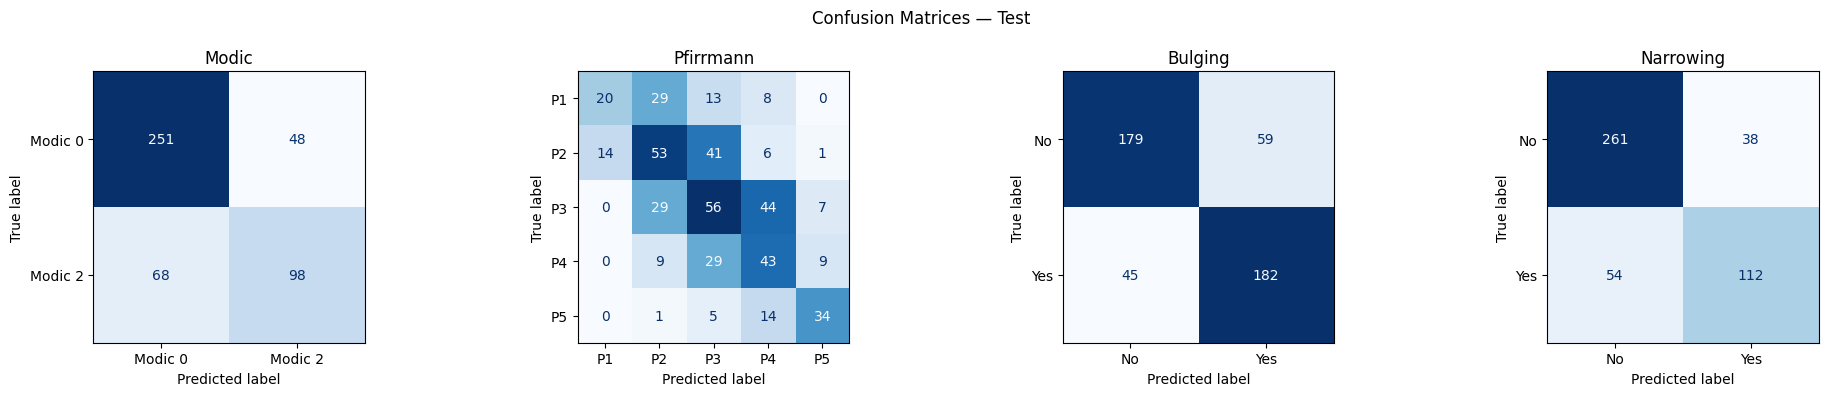

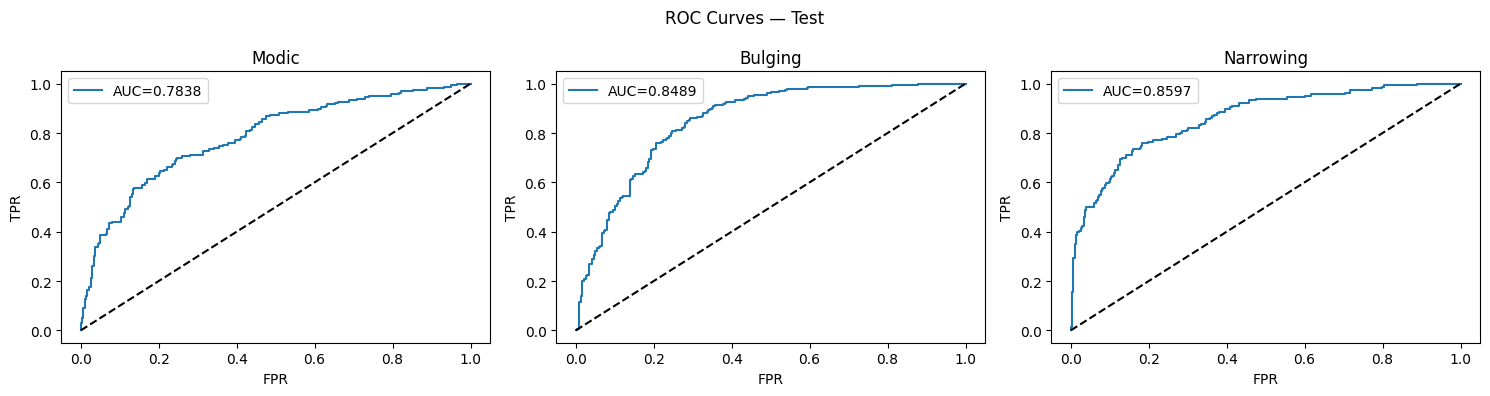

In [14]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("GPU:", torch.cuda.get_device_name(0))

DATA_DIR     = "/kaggle/input/datasets/prasanth6/lumbar-spine-disc/disc_samples_final_v2"
TARGET_SHAPE = (32, 128, 128)
BATCH_SIZE   = 4
EPOCHS       = 25
LR           = 1e-4
PATIENCE     = 5

# =========================================================
# DATASET — resize + z-score
# =========================================================
class DiscDataset(Dataset):
    def __init__(self, files, target_shape=TARGET_SHAPE):
        self.target_shape = target_shape
        self.files = []
        skipped = 0
        for f in files:
            try:
                data  = np.load(f, allow_pickle=True)
                modic = int(data["labels"].item()["modic"])
                if modic in [0, 2]:
                    self.files.append(f)
                else:
                    skipped += 1
            except Exception as e:
                print(f"  [WARN] {f}: {e}")
                skipped += 1
        print(f"  Loaded {len(self.files)} samples | skipped {skipped}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data  = np.load(self.files[idx], allow_pickle=True)
        image = torch.tensor(data["image"],
                             dtype=torch.float32).unsqueeze(0)
        # Resize to fixed shape
        image = F.interpolate(
            image.unsqueeze(0), size=self.target_shape,
            mode="trilinear", align_corners=False
        ).squeeze(0)
        # Z-score normalise per volume
        image = (image - image.mean()) / (image.std() + 1e-6)

        labels    = data["labels"].item()
        modic_raw = int(labels["modic"])
        pfirrmann = max(0, min(int(labels["pfirrmann"]) - 1, 4))

        return image, {
            "modic":     torch.tensor(
                0 if modic_raw == 0 else 1, dtype=torch.long),
            "pfirrmann": torch.tensor(pfirrmann, dtype=torch.long),
            "bulging":   torch.tensor(
                float(labels["bulging"]), dtype=torch.float32),
            "narrowing": torch.tensor(
                float(labels["narrowing"]), dtype=torch.float32),
        }


# =========================================================
# STRATIFIED SPLIT — filter before splitting
# =========================================================
all_files = sorted([
    os.path.join(DATA_DIR, f)
    for f in os.listdir(DATA_DIR) if f.endswith(".npz")
])
print(f"Total .npz files: {len(all_files)}")

labels_for_split, valid_files = [], []
for f in all_files:
    try:
        d = np.load(f, allow_pickle=True)
        m = int(d["labels"].item()["modic"])
        if m in [0, 2]:
            labels_for_split.append(m)
            valid_files.append(f)
    except Exception:
        pass

print(f"Valid files (modic 0 or 2): {len(valid_files)}")

train_files, temp_files, _, temp_labels = train_test_split(
    valid_files, labels_for_split,
    test_size=0.30, stratify=labels_for_split, random_state=42
)
val_files, test_files = train_test_split(
    temp_files, test_size=0.50,
    stratify=temp_labels, random_state=42
)
print(f"\nSplit → Train:{len(train_files)} Val:{len(val_files)} Test:{len(test_files)}")

print("\nBuilding Train dataset:")
train_ds = DiscDataset(train_files)
print("Building Val dataset:")
val_ds   = DiscDataset(val_files)
print("Building Test dataset:")
test_ds  = DiscDataset(test_files)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)


# =========================================================
# 3D CNN
#
# A straightforward volumetric CNN with progressively
# deeper and wider convolutional blocks, designed for
# strong baseline performance on 3D medical images.
#
# Architecture:
#   Block 1:  1  →  32  (2× Conv3D, MaxPool)
#   Block 2:  32 →  64  (2× Conv3D, MaxPool)
#   Block 3:  64 → 128  (3× Conv3D, MaxPool)
#   Block 4: 128 → 256  (3× Conv3D, MaxPool)
#   Block 5: 256 → 512  (3× Conv3D, AdaptiveAvgPool)
#   Classifier: 512 → task heads
# =========================================================

class ConvBnRelu3D(nn.Module):
    """Conv3D → GroupNorm → ReLU unit."""
    def __init__(self, in_ch, out_ch, kernel=3, stride=1, padding=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, kernel,
                      stride=stride, padding=padding, bias=False),
            nn.GroupNorm(max(1, out_ch // 8), out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class CNN3D(nn.Module):
    """
    Five-block 3D CNN with multi-conv blocks, MaxPool
    downsampling, and task-specific MLP heads.
    """
    def __init__(self):
        super().__init__()

        # Block 1 — shallow features
        self.block1 = nn.Sequential(
            ConvBnRelu3D(1,   32),
            ConvBnRelu3D(32,  32),
            nn.MaxPool3d(2)
        )

        # Block 2
        self.block2 = nn.Sequential(
            ConvBnRelu3D(32,  64),
            ConvBnRelu3D(64,  64),
            nn.MaxPool3d(2)
        )

        # Block 3
        self.block3 = nn.Sequential(
            ConvBnRelu3D(64,  128),
            ConvBnRelu3D(128, 128),
            ConvBnRelu3D(128, 128),
            nn.MaxPool3d(2)
        )

        # Block 4
        self.block4 = nn.Sequential(
            ConvBnRelu3D(128, 256),
            ConvBnRelu3D(256, 256),
            ConvBnRelu3D(256, 256),
            nn.MaxPool3d(2)
        )

        # Block 5 — deep semantic features
        self.block5 = nn.Sequential(
            ConvBnRelu3D(256, 512),
            ConvBnRelu3D(512, 512),
            ConvBnRelu3D(512, 512),
        )

        self.pool    = nn.AdaptiveAvgPool3d(1)
        self.dropout = nn.Dropout(0.3)

        # Task heads — modic binary (Modic 0 vs Modic 2)
        self.head_modic = nn.Sequential(
            nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 2))
        self.head_pfirrmann = nn.Sequential(
            nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 5))
        self.head_bulging = nn.Sequential(
            nn.Linear(512, 128), nn.ReLU(),
            nn.Linear(128, 64),  nn.ReLU(),
            nn.Linear(64, 1))
        self.head_narrowing = nn.Sequential(
            nn.Linear(512, 128), nn.ReLU(),
            nn.Linear(128, 64),  nn.ReLU(),
            nn.Linear(64, 1))

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = self.dropout(self.pool(x).flatten(1))

        return {
            "modic":     self.head_modic(x),
            "pfirrmann": self.head_pfirrmann(x),
            "bulging":   self.head_bulging(x).squeeze(1),
            "narrowing": self.head_narrowing(x).squeeze(1),
        }


# =========================================================
# LOSS
# =========================================================
ce  = nn.CrossEntropyLoss()
bce = nn.BCEWithLogitsLoss()

def multitask_loss(out, tgt):
    return (
        ce( out["modic"],     tgt["modic"])     +
        ce( out["pfirrmann"], tgt["pfirrmann"]) +
        bce(out["bulging"],   tgt["bulging"])   +
        bce(out["narrowing"], tgt["narrowing"])
    )


# =========================================================
# TRAIN / EVAL
# =========================================================
model     = CNN3D().to(device)
optimizer = torch.optim.AdamW(model.parameters(),
                               lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS)
scaler    = GradScaler(enabled=True)

n_params = sum(p.numel() for p in model.parameters()
               if p.requires_grad)
print(f"\nCNN3D params: {n_params:,}")


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total = 0.0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for img, tgt in loader:
            img = img.to(device)
            tgt = {k: v.to(device) for k, v in tgt.items()}
            if train:
                optimizer.zero_grad()
            with autocast(device.type):
                out  = model(img)
                loss = multitask_loss(out, tgt)
            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total += loss.item()
    return total / max(len(loader), 1)


train_losses, val_losses = [], []
best_val = np.inf
counter  = 0

for epoch in range(EPOCHS):
    tr = run_epoch(train_loader, train=True)
    vl = run_epoch(val_loader,   train=False)
    scheduler.step()
    train_losses.append(tr)
    val_losses.append(vl)
    print(f"Epoch {epoch+1:02d}/{EPOCHS}  |  "
          f"Train {tr:.4f}  |  Val {vl:.4f}")
    if vl < best_val:
        best_val = vl; counter = 0
        torch.save(model.state_dict(), "best_cnn3d.pth")
        print("  ✔ Saved best model")
    else:
        counter += 1
        if counter >= PATIENCE:
            print("Early stopping."); break

plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train")
plt.plot(val_losses,   label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("3D CNN — Loss")
plt.legend(); plt.tight_layout(); plt.show()


# =========================================================
# EVALUATION
# =========================================================
def evaluate(loader, split_name="Test"):
    model.load_state_dict(
        torch.load("best_cnn3d.pth", map_location=device))
    model.eval()

    preds = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}
    probs = {k: [] for k in ["modic", "bulging", "narrowing"]}
    gts   = {k: [] for k in
             ["modic", "pfirrmann", "bulging", "narrowing"]}

    with torch.no_grad():
        for img, tgt in loader:
            img = img.to(device)
            out = model(img)

            p_m = torch.softmax(out["modic"], 1)[:, 1]
            probs["modic"].extend(p_m.cpu().numpy())
            preds["modic"].extend(
                out["modic"].argmax(1).cpu().numpy())
            gts["modic"].extend(tgt["modic"].numpy())

            preds["pfirrmann"].extend(
                out["pfirrmann"].argmax(1).cpu().numpy())
            gts["pfirrmann"].extend(tgt["pfirrmann"].numpy())

            p_b = torch.sigmoid(out["bulging"])
            probs["bulging"].extend(p_b.cpu().numpy())
            preds["bulging"].extend(
                (p_b > 0.5).long().cpu().numpy())
            gts["bulging"].extend(
                tgt["bulging"].long().numpy())

            p_n = torch.sigmoid(out["narrowing"])
            probs["narrowing"].extend(p_n.cpu().numpy())
            preds["narrowing"].extend(
                (p_n > 0.5).long().cpu().numpy())
            gts["narrowing"].extend(
                tgt["narrowing"].long().numpy())

    task_labels = {
        "modic":     (["Modic 0", "Modic 2"],
                      f"\nMODIC — {split_name}"),
        "pfirrmann": ([f"P{i+1}" for i in range(5)],
                      f"\nPFIRRMANN — {split_name}"),
        "bulging":   (["No", "Yes"],
                      f"\nBULGING — {split_name}"),
        "narrowing": (["No", "Yes"],
                      f"\nNARROWING — {split_name}"),
    }
    for task, (names, title) in task_labels.items():
        print(title)
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i < len(names)]
        print(classification_report(
            gts[task], preds[task], labels=present,
            target_names=used, digits=4, zero_division=0))

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    fig.suptitle(f"Confusion Matrices — {split_name}")
    for ax, (task, (names, _)) in zip(axes, task_labels.items()):
        present = sorted(set(gts[task]))
        used    = [names[i] for i in present if i < len(names)]
        ConfusionMatrixDisplay(
            confusion_matrix(gts[task], preds[task]),
            display_labels=used
        ).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(task.capitalize())
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"ROC Curves — {split_name}")
    for ax, task in zip(axes, ["modic", "bulging", "narrowing"]):
        gt_arr   = np.array(gts[task])
        prob_arr = np.array(probs[task])
        if len(np.unique(gt_arr)) < 2:
            ax.set_title(f"{task} (1 class)"); continue
        fpr, tpr, _ = roc_curve(gt_arr, prob_arr)
        ax.plot(fpr, tpr, label=f"AUC={auc(fpr, tpr):.4f}")
        ax.plot([0, 1], [0, 1], "k--")
        ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
        ax.set_title(task.capitalize()); ax.legend()
    plt.tight_layout(); plt.show()


evaluate(val_loader,  split_name="Validation")
evaluate(test_loader, split_name="Test")